# AIORI 3 Hackathon · PS-003 · Phase 1
## Federated Traffic-Flow Prediction with Communication-Cost Evaluation

**Team:** PRISM Lab, IIT Guwahati

This notebook is a complete, self-contained **federated learning simulator** for traffic-flow
forecasting on the PeMS-03, PeMS-04, PeMS-07 and PeMS-08 datasets. It implements everything
PS-003 asks for and records every byte that crosses the simulated network.

### How PS-003 requirements map to this notebook

| PS-003 requirement | Where it is implemented |
|---|---|
| One public traffic dataset split across 3 to 5 simulated clients | Section 4 (`K = 4` clients, sensors = intersections). PeMS-04 is the primary dataset, the other three show generalisation |
| FedAvg with one compact forecasting model | Sections 6 and 9 (`CompactGRU`, about 4 K parameters at the default size) |
| Chronological train/test splits to avoid leakage | Section 3 (60 / 20 / 20 split in time, scaler fitted on train only) |
| Compare IID and non-IID client distributions | Section 4 (random vs volume-stratified sensor partitions, heterogeneity measured by Jensen-Shannon divergence) |
| Measure MAE / RMSE, communication bytes per round and convergence | Sections 7, 8, 9 (bytes are measured from real serialised payloads, not only estimated) |
| Run experiments using 3 random seeds | Section 11 (seeds 0, 1, 2; every table reports mean ± std) |
| Centralised and federated baselines | Section 9 (centralised, local-only, FedAvg) |
| Communication-cost and convergence analysis | Sections 12 to 14 (trade-off sweep, Pareto front, convergence rounds) |

### How to run
1. Put `PEMS03.npz`, `PEMS04.npz`, `PEMS07.npz`, `PEMS08.npz` in `MyDrive/AIORI_PS003/data/`.
2. `Runtime → Change runtime type → T4 GPU`.
3. To train, set `TRAIN_MISSING_RUNS = True` in Section 1, then run all cells top to bottom.
   Every finished run is saved to Drive, so if Colab disconnects
   simply run all cells again: completed runs are skipped automatically.
4. Open the TensorBoard dashboard (Section 10) to watch training live.

Set `SMOKE_TEST = True` in Section 1 for a two-minute check that everything works before the full run.

### Presenting without retraining (results-only mode)
This is the default (`TRAIN_MISSING_RUNS = False` in Section 1). The notebook **only loads the saved runs from
Drive**, never trains, and needs **no GPU** (a free CPU runtime is enough). Runs that have not been
trained yet are listed and skipped. Run all cells: the tables, figures and the live demo in
Section 15 are ready in about 2 to 4 minutes, and TensorBoard shows the saved training curves.

## 1. Environment setup

Mounts Google Drive (when running on Colab), imports libraries and selects the GPU.
Nothing needs to be installed: PyTorch, TensorBoard, NumPy, pandas and Matplotlib are
preinstalled on Colab.

In [ ]:
import os
import json
import math
import time
import random
import hashlib
from dataclasses import dataclass, asdict, field, replace
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.tensorboard import SummaryWriter

# ---- Colab / Google Drive -------------------------------------------------------------------
try:
    from google.colab import drive  # type: ignore
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:  # running locally (e.g. Jupyter on a workstation)
    IN_COLAB = False

# ---- Paths (edit these if your Drive folders are named differently) -------------------------
PROJECT_DIR = os.environ.get("PS003_PROJECT_DIR", "/content/drive/MyDrive/AIORI_PS003")
DATA_DIR = os.environ.get("PS003_DATA_DIR", os.path.join(PROJECT_DIR, "data"))
OUT_DIR = os.environ.get("PS003_OUT_DIR", os.path.join(PROJECT_DIR, "phase1_outputs"))

# Quick end-to-end check: 1 dataset, 1 seed, 3 rounds, small data subsample.
SMOKE_TEST = os.environ.get("PS003_SMOKE", "0") == "1"

# False = results-only mode (default): load saved runs, never train, works on a CPU runtime.
# True  = train every run that is not saved yet (needs a GPU runtime). Use this for the
#         trade-off sweep in Section 13; finished runs are always skipped.
TRAIN_MISSING_RUNS = os.environ.get("PS003_TRAIN", "0") == "1"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Running on Colab: {IN_COLAB}")
print(f"Device          : {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))
print(f"PyTorch         : {torch.__version__}")
print(f"Data directory  : {DATA_DIR}")
print(f"Output directory: {OUT_DIR}")
print(f"Smoke test      : {SMOKE_TEST}")
print(f"Train missing   : {TRAIN_MISSING_RUNS}" + ("" if TRAIN_MISSING_RUNS else "   (results-only mode)"))

Mounted at /content/drive
Running on Colab: True
Device          : cpu
PyTorch         : 2.11.0+cpu
Data directory  : /content/drive/MyDrive/AIORI_PS003/data
Output directory: /content/drive/MyDrive/AIORI_PS003/phase1_outputs
Smoke test      : False
Train missing   : False   (results-only mode)


## 2. Experiment configuration

Every hyperparameter lives in one place. The defaults were chosen for a **low communication
cost**: the model is deliberately compact, because in federated learning every parameter is
transmitted twice per client per round (download and upload).

**Why a hidden size of 32?** The model size, not the dataset size, decides the per-round cost.
A 1-layer GRU with 32 hidden units has about 4 K parameters (about 16 KB in float32). Section 13
sweeps 16 / 32 / 64 hidden units and three wire formats to show the accuracy versus bytes trade-off
explicitly, so the choice is justified by data rather than assumed.

In [ ]:
@dataclass
class Config:
    # ----- Data -----
    datasets: Tuple[str, ...] = ("PEMS03", "PEMS04", "PEMS07", "PEMS08")
    primary_dataset: str = "PEMS04"   # PS-003 asks for one dataset; PeMS-04 is the headline one
    input_len: int = 12               # 12 x 5 min = 1 hour of history
    horizon: int = 12                 # predict the next 12 x 5 min = 1 hour
    train_frac: float = 0.6           # chronological split: first 60 % of days
    val_frac: float = 0.2             # next 20 % for model selection; last 20 % is the test set

    # ----- Federation -----
    num_clients: int = 4              # PS-003: 3 to 5 simulated clients
    seeds: Tuple[int, ...] = (0, 1, 2)  # PS-003: 3 random seeds

    # ----- Model -----
    hidden_size: int = 32
    num_layers: int = 1

    # ----- Optimisation -----
    rounds: int = 40                  # FedAvg communication rounds
    local_epochs: int = 1             # epochs each client trains per round
    lr: float = 2e-3
    seqs_per_batch: int = 4096        # sensor-sequences per mini-batch (same for every method)
    grad_clip: float = 5.0

    # ----- Communication -----
    codec: str = "fp32"               # wire format of model updates: fp32 | fp16 | int8
    raw_bytes_per_reading: int = 2    # centralised baseline ships raw counts as uint16 (2 bytes)

    # ----- Convergence -----
    conv_tol: float = 0.05            # "converged" = first round within 5 % of the run's best val MAE

    # ----- Trade-off sweep (primary dataset, non-IID) -----
    sweep_hidden: Tuple[int, ...] = (16, 32, 64)
    sweep_codecs: Tuple[str, ...] = ("fp32", "fp16", "int8")
    sweep_local_epochs: Tuple[int, ...] = (2, 4)   # fewer rounds, more local work, same total epochs

    # ----- Smoke test only -----
    max_windows: Optional[int] = None  # subsample windows per split (None = use all data)

    # ----- Outputs -----
    fig_dpi: int = 300                # 300 dpi -> every figure is well above Full HD


CFG = Config()
if SMOKE_TEST:
    CFG = replace(CFG, datasets=("PEMS08",), primary_dataset="PEMS08", seeds=(0,),
                  rounds=3, max_windows=150, sweep_hidden=(16, 32), sweep_codecs=("fp32", "int8"),
                  sweep_local_epochs=(3,))
    OUT_DIR = OUT_DIR.rstrip("/") + "_smoke"

RUNS_DIR = os.path.join(OUT_DIR, "runs")          # one JSON per finished run (enables resume)
CKPT_DIR = os.path.join(OUT_DIR, "checkpoints")   # best model weights per run
TB_DRIVE_DIR = os.path.join(OUT_DIR, "tensorboard")  # permanent copy of the dashboard logs
# TensorBoard reads live from local disk: Google Drive syncs files with a delay, so a dashboard
# pointed straight at Drive often shows "No dashboards are active". Logs are mirrored to Drive
# after every run so they survive a disconnect.
TB_DIR = (os.path.join("/content/tb_logs", os.path.basename(OUT_DIR.rstrip("/")))
          if IN_COLAB else TB_DRIVE_DIR)
FIG_DIR = os.path.join(OUT_DIR, "figures")        # 300 dpi PNG + vector PDF
TAB_DIR = os.path.join(OUT_DIR, "tables")         # CSV, Markdown and LaTeX tables
for d in (RUNS_DIR, CKPT_DIR, TB_DIR, TB_DRIVE_DIR, FIG_DIR, TAB_DIR):
    os.makedirs(d, exist_ok=True)

import shutil
if TB_DIR != TB_DRIVE_DIR:   # after a disconnect, bring back the logs of runs already finished
    shutil.copytree(TB_DRIVE_DIR, TB_DIR, dirs_exist_ok=True)

print(json.dumps(asdict(CFG), indent=2))

{
  "datasets": [
    "PEMS03",
    "PEMS04",
    "PEMS07",
    "PEMS08"
  ],
  "primary_dataset": "PEMS04",
  "input_len": 12,
  "horizon": 12,
  "train_frac": 0.6,
  "val_frac": 0.2,
  "num_clients": 4,
  "seeds": [
    0,
    1,
    2
  ],
  "hidden_size": 32,
  "num_layers": 1,
  "rounds": 40,
  "local_epochs": 1,
  "lr": 0.002,
  "seqs_per_batch": 4096,
  "grad_clip": 5.0,
  "codec": "fp32",
  "raw_bytes_per_reading": 2,
  "conv_tol": 0.05,
  "sweep_hidden": [
    16,
    32,
    64
  ],
  "sweep_codecs": [
    "fp32",
    "fp16",
    "int8"
  ],
  "sweep_local_epochs": [
    2,
    4
  ],
  "max_windows": null,
  "fig_dpi": 300
}


## 3. Reproducibility and data loading

**Seeds.** Python, NumPy and PyTorch are seeded and cuDNN is put in deterministic mode, so a run
with the same seed gives the same numbers.

**What the `.npz` files contain.** Each file holds one array `data` of shape `(T, N, C)`: `T`
five-minute time steps, `N` loop-detector sensors, `C` channels. PeMS-04 and PeMS-08 carry three
channels (flow, occupancy, speed); PeMS-03 and PeMS-07 carry flow only. **We use channel 0
(flow, vehicles per 5 minutes) for every dataset** so the four results are directly comparable.

**Input features.** Each sensor's model input at every step is 4 numbers:
normalised flow, `sin` and `cos` of time-of-day, and a weekend flag. Time features are derived
from the clock, so they cost nothing to transmit. The start dates come from the dataset
descriptions (STSGCN, AAAI 2020) and only affect the weekend flag.

**Chronological split (no leakage).** The time axis is cut into the first 60 % (train), next
20 % (validation) and last 20 % (test). A window is used in a split only if its entire
input-plus-target span lies inside that split, so no test value is ever seen during training,
and the normalisation statistics are computed from training data only.

In [ ]:
def set_seed(seed: int) -> None:
    """Seed every random number generator used in the simulator."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# First recorded day of each dataset (Monday = 0 ... Sunday = 6).
DATASET_START = {
    "PEMS03": ("2018-09-01", 5),   # Saturday
    "PEMS04": ("2018-01-01", 0),   # Monday
    "PEMS07": ("2017-05-01", 0),   # Monday
    "PEMS08": ("2016-07-01", 4),   # Friday
}
STEPS_PER_DAY = 288  # 24 h x 12 five-minute intervals


@dataclass
class DatasetBundle:
    """Everything known about one dataset after loading. Arrays live in CPU memory."""
    name: str
    flow: np.ndarray                 # (T, N) raw flow, vehicles per 5 min
    time_feats: np.ndarray           # (T, 3) sin(tod), cos(tod), weekend flag
    splits: Dict[str, Tuple[int, int]]  # split name -> [start, end) on the time axis

    @property
    def T(self) -> int:
        return self.flow.shape[0]

    @property
    def N(self) -> int:
        return self.flow.shape[1]

    @property
    def flow_train(self) -> np.ndarray:
        a, b = self.splits["train"]
        return self.flow[a:b]


def load_dataset(name: str, cfg: Config) -> DatasetBundle:
    """Load one PeMS .npz file, keep the flow channel, build time features and split indices."""
    path = os.path.join(DATA_DIR, f"{name}.npz")
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"{path} not found. Upload {name}.npz to {DATA_DIR} (see 'How to run').")
    raw = np.load(path)["data"]
    flow = raw[..., 0].astype(np.float32)          # channel 0 = flow
    flow = np.nan_to_num(flow, nan=0.0)
    T = flow.shape[0]

    t = np.arange(T)
    tod = (t % STEPS_PER_DAY) / STEPS_PER_DAY
    _, start_dow = DATASET_START[name]
    dow = (start_dow + t // STEPS_PER_DAY) % 7
    time_feats = np.stack([np.sin(2 * np.pi * tod),
                           np.cos(2 * np.pi * tod),
                           (dow >= 5).astype(np.float64)], axis=1).astype(np.float32)

    n_train = int(T * cfg.train_frac)
    n_val = int(T * cfg.val_frac)
    splits = {"train": (0, n_train),
              "val": (n_train, n_train + n_val),
              "test": (n_train + n_val, T)}
    return DatasetBundle(name, flow, time_feats, splits)


# Quick inventory of the four datasets (also confirms the files are in place).
_inventory = []
for _name in CFG.datasets:
    _b = load_dataset(_name, CFG)
    _inventory.append({
        "dataset": _name, "time steps": _b.T, "sensors": _b.N,
        "days": round(_b.T / STEPS_PER_DAY, 1), "start date": DATASET_START[_name][0],
        "train/val/test steps": "/".join(str(b - a) for a, b in _b.splits.values()),
        "mean flow": round(float(_b.flow.mean()), 1), "max flow": int(_b.flow.max()),
        "zero readings %": round(100 * float((_b.flow == 0).mean()), 2),
    })
    del _b
print(pd.DataFrame(_inventory).to_string(index=False))

dataset  time steps  sensors  days start date train/val/test steps  mean flow  max flow  zero readings %
 PEMS03       26208      358  91.0 2018-09-01      15724/5241/5243      179.3      1852             0.67
 PEMS04       16992      307  59.0 2018-01-01      10195/3398/3399      211.7       919             1.59
 PEMS07       28224      883  98.0 2017-05-01      16934/5644/5646      308.5      1498             0.45
 PEMS08       17856      170  62.0 2016-07-01      10713/3571/3572      230.7      1147             0.35


## 4. Simulated intersections: IID and non-IID client partitions

Each **client** is a group of road sensors (a simulated cluster of intersections owned by one
edge server). Every sensor belongs to exactly one client, and a client never shares its raw
readings. With `K = 4` clients this is **horizontal, cross-silo** federated learning: all
clients have the same features (flow plus time) for different sensors.

* **IID partition.** Sensors are shuffled at random (seeded) and dealt out in equal shares, so
  every client sees the same mix of quiet and busy roads.
* **Non-IID partition (volume-stratified).** Sensors are sorted by their mean training-period flow
  and cut into `K` contiguous bands. Client 1 holds the quietest sensors, client 4 the busiest
  freeway mainlines. Client sizes stay equal, so the *only* difference from IID is the
  distribution skew. This is feature and label skew, the hardest case for FedAvg.

**Measuring the heterogeneity.** For each client we compare its flow histogram with the global
histogram using the Jensen-Shannon divergence (0 = identical, 1 = disjoint, base 2) and report the
mean over clients. IID partitions should score close to 0, non-IID clearly higher.

In [ ]:
def partition_sensors(bundle: DatasetBundle, num_clients: int, scheme: str, seed: int) -> List[np.ndarray]:
    """Return a list of sensor-index arrays, one per client.

    scheme = "iid"    : random equal split (depends on seed)
    scheme = "noniid" : volume-stratified equal split (deterministic)
    scheme = "all"    : one client with every sensor (centralised training)
    """
    N = bundle.N
    if scheme == "all":
        return [np.arange(N)]
    if scheme == "iid":
        order = np.random.default_rng(seed).permutation(N)
    elif scheme == "noniid":
        order = np.argsort(bundle.flow_train.mean(axis=0), kind="stable")
    else:
        raise ValueError(f"unknown partition scheme '{scheme}'")
    return [np.sort(part) for part in np.array_split(order, num_clients)]


def js_divergence(p: np.ndarray, q: np.ndarray) -> float:
    """Jensen-Shannon divergence between two histograms, base 2 (range 0 to 1)."""
    p = p / p.sum()
    q = q / q.sum()
    m = 0.5 * (p + q)

    def kl(a, b):
        mask = a > 0
        return float(np.sum(a[mask] * np.log2(a[mask] / b[mask])))
    return 0.5 * kl(p, m) + 0.5 * kl(q, m)


def heterogeneity_report(bundle: DatasetBundle, parts: List[np.ndarray], bins: int = 60) -> Dict:
    """Quantify how different each client's training data is from the global distribution."""
    x = bundle.flow_train
    edges = np.linspace(0.0, float(x.max()) + 1e-6, bins + 1)
    global_hist, _ = np.histogram(x, bins=edges)
    js = [js_divergence(np.histogram(x[:, p], bins=edges)[0].astype(float), global_hist.astype(float))
          for p in parts]
    return {
        "js_per_client": [round(v, 4) for v in js],
        "js_mean": round(float(np.mean(js)), 4),
        "client_sensors": [int(len(p)) for p in parts],
        "client_mean_flow": [round(float(x[:, p].mean()), 2) for p in parts],
        "client_std_flow": [round(float(x[:, p].std()), 2) for p in parts],
    }


# Show the heterogeneity of both partitions for every dataset (seed 0).
_rows = []
for _name in CFG.datasets:
    _b = load_dataset(_name, CFG)
    for _scheme in ("iid", "noniid"):
        _r = heterogeneity_report(_b, partition_sensors(_b, CFG.num_clients, _scheme, seed=0))
        _rows.append({"dataset": _name, "partition": _scheme, "JS mean": _r["js_mean"],
                      "sensors per client": _r["client_sensors"],
                      "mean flow per client": _r["client_mean_flow"]})
    del _b
print(pd.DataFrame(_rows).to_string(index=False))

dataset partition  JS mean   sensors per client             mean flow per client
 PEMS03       iid   0.0015     [90, 90, 89, 89]  [189.84, 181.38, 169.21, 185.0]
 PEMS03    noniid   0.1401     [90, 90, 89, 89]  [58.86, 142.66, 229.74, 296.09]
 PEMS04       iid   0.0020     [77, 77, 77, 76]  [207.19, 201.75, 196.1, 224.13]
 PEMS04    noniid   0.0910     [77, 77, 77, 76]   [99.71, 166.4, 235.95, 328.47]
 PEMS07       iid   0.0009 [221, 221, 221, 220] [309.84, 303.01, 306.33, 318.95]
 PEMS07    noniid   0.1154 [221, 221, 221, 220]  [160.86, 276.91, 350.0, 450.95]
 PEMS08       iid   0.0045     [43, 43, 42, 42] [246.69, 223.18, 224.13, 224.41]
 PEMS08    noniid   0.1295     [43, 43, 42, 42]  [103.64, 204.27, 267.85, 346.5]


## 5. Federated normalisation and on-device batching

**Normalisation without sharing data.** The model trains on z-scored flow
`(x - mean) / std`. A single global mean and standard deviation is needed so that every client
speaks the same numeric "language", but no client may reveal its raw data. Each client therefore
sends only three numbers computed on its own training slice: count, sum, and sum of squares
(3 x 8 bytes). The server combines them into the exact global mean and std and sends those two
numbers back (2 x 4 bytes). This one-off cost is recorded as **setup bytes** in the ledger.

**Batching.** A client's data stays on the GPU as a `(T, N_k)` tensor. A mini-batch is a set of
window start times; for each start we cut 12 input steps and the following 12 target steps for
every sensor the client owns. Each sensor's window becomes one sequence, so a batch is
`(windows x sensors, 12, 4)`. The number of sequences per batch is fixed (`seqs_per_batch`) for
every method, so centralised, local and federated training take the same number of gradient
steps per epoch over the whole dataset.

In [ ]:
SETUP_UP_BYTES_PER_CLIENT = 3 * 8    # count, sum, sum of squares (float64)
SETUP_DOWN_BYTES_PER_CLIENT = 2 * 4  # mean, std (float32)


def federated_scaler(bundle: DatasetBundle, parts: List[np.ndarray]) -> Tuple[float, float]:
    """Exact global mean/std from per-client sufficient statistics (no raw data leaves a client)."""
    n = s = ss = 0.0
    for p in parts:                                  # computed locally on each client
        x = bundle.flow_train[:, p].astype(np.float64)
        n += x.size
        s += x.sum()
        ss += np.square(x).sum()
    mean = s / n                                     # combined on the server
    std = math.sqrt(max(ss / n - mean ** 2, 1e-12))
    return float(mean), float(std)


class ClientData:
    """One client's private data, held on the training device, plus a mini-batch generator."""

    def __init__(self, bundle: DatasetBundle, sensors: np.ndarray, mean: float, std: float,
                 cfg: Config, device: torch.device):
        self.sensors = sensors
        self.n_sensors = len(sensors)
        self.L, self.H = cfg.input_len, cfg.horizon
        self.device = device
        raw = bundle.flow[:, sensors]
        self.flow_raw = torch.tensor(raw, device=device)                 # (T, N_k)
        self.flow_z = torch.tensor((raw - mean) / std, device=device)    # (T, N_k)
        self.time_feats = torch.tensor(bundle.time_feats, device=device) # (T, 3)
        self.ar_in = torch.arange(self.L, device=device)
        self.ar_out = torch.arange(self.L, self.L + self.H, device=device)

        # Valid window start indices per split: the whole input+target span must fit inside.
        self.starts = {}
        for split, (a, b) in bundle.splits.items():
            s = np.arange(a, b - self.L - self.H + 1)
            if cfg.max_windows is not None and len(s) > cfg.max_windows:
                s = s[np.linspace(0, len(s) - 1, cfg.max_windows).astype(int)]
            self.starts[split] = s
        self.batch_windows = max(1, cfg.seqs_per_batch // self.n_sensors)

    def num_sequences(self, split: str) -> int:
        """Number of (window, sensor) training sequences: the FedAvg weight of this client."""
        return len(self.starts[split]) * self.n_sensors

    def make_batch(self, starts: torch.Tensor):
        """Build model inputs and targets for a set of window start times."""
        B, Nk = len(starts), self.n_sensors
        idx_in = starts[:, None] + self.ar_in                       # (B, L)
        idx_out = starts[:, None] + self.ar_out                     # (B, H)
        flow_in = self.flow_z[idx_in].unsqueeze(-1)                 # (B, L, Nk, 1)
        tf = self.time_feats[idx_in].unsqueeze(2).expand(B, self.L, Nk, 3)
        x = torch.cat([flow_in, tf], dim=-1)                        # (B, L, Nk, 4)
        x = x.permute(0, 2, 1, 3).reshape(B * Nk, self.L, 4)        # one sequence per sensor
        y_z = self.flow_z[idx_out].permute(0, 2, 1).reshape(B * Nk, self.H)
        y_raw = self.flow_raw[idx_out].permute(0, 2, 1).reshape(B * Nk, self.H)
        return x, y_z, y_raw

    def iter_batches(self, split: str, shuffle: bool = False,
                     rng: Optional[np.random.Generator] = None, scale: int = 1):
        starts = self.starts[split]
        if shuffle:
            starts = starts[rng.permutation(len(starts))]
        bw = self.batch_windows * scale
        for i in range(0, len(starts), bw):
            yield self.make_batch(torch.as_tensor(starts[i:i + bw], device=self.device))


def build_clients(bundle: DatasetBundle, parts: List[np.ndarray], cfg: Config):
    """Create the client objects plus the global scaler (computed federatedly)."""
    mean, std = federated_scaler(bundle, parts)
    clients = [ClientData(bundle, p, mean, std, cfg, DEVICE) for p in parts]
    return clients, mean, std

## 6. The compact forecasting model

`CompactGRU` is one small Gated Recurrent Unit shared by **all sensors**. It reads the last hour
of one sensor (12 steps x 4 features) and outputs the next hour (12 flow values) in a single shot.
Because the same weights serve every sensor, the model size does **not** grow with the number of
sensors. This is the key property that keeps federated communication cheap: PeMS-07 with 883
sensors costs exactly the same bytes per round as PeMS-08 with 170 sensors.

Parameter count for input size `F = 4`, hidden size `h`, horizon 12:
`GRU: 3 (F h + h h + 2 h)` plus `head: 12 h + 12`. For `h = 32` this is 3,648 + 396 = **4,044 parameters**.

In [ ]:
class CompactGRU(nn.Module):
    """Sensor-shared GRU forecaster: (batch, 12, 4) -> (batch, 12)."""

    def __init__(self, in_features: int = 4, hidden: int = 32, layers: int = 1, horizon: int = 12):
        super().__init__()
        self.gru = nn.GRU(in_features, hidden, num_layers=layers, batch_first=True)
        self.head = nn.Linear(hidden, horizon)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out, _ = self.gru(x)              # (batch, 12, hidden)
        return self.head(out[:, -1])      # last hidden state -> 12-step forecast


def count_params(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters())


for _h in (16, 32, 64):
    _m = CompactGRU(hidden=_h)
    print(f"hidden={_h:>3}: {count_params(_m):>6,} parameters = {4 * count_params(_m) / 1024:6.1f} KB in float32")

hidden= 16:  1,260 parameters =    4.9 KB in float32
hidden= 32:  4,044 parameters =   15.8 KB in float32
hidden= 64: 14,220 parameters =   55.5 KB in float32


## 7. The communication layer: codecs and the byte ledger

Every message in the simulator is **actually serialised to bytes** and its length is recorded,
so the reported cost is measured, not just estimated. Clients and server exchange *model deltas*
(new weights minus the weights the client already holds), which are small and centred on zero
and therefore compress well.

| Codec | Encoding | Bytes per message (P parameters, n tensors) |
|---|---|---|
| `fp32` | IEEE float32, lossless | `4 P` |
| `fp16` | IEEE float16 | `2 P` |
| `int8` | symmetric per-tensor 8-bit quantisation plus one float32 scale per tensor | `P + 4 n` |

**No drift with lossy codecs.** The server keeps a copy of exactly what the clients hold
(`client_view`). The downlink sends `global - client_view`, quantised; whatever the quantiser
rounds away stays in that difference and is sent in the next round (error feedback), so the
clients' copy never drifts away from the server model.

Transport headers (TCP/IP, TLS, gRPC framing) add a small constant per message and are not
included; we report pure payload bytes, which is the standard practice in FL papers.

In [ ]:
class Codec:
    """Serialises a list of float32 tensors to bytes and back."""

    def __init__(self, name: str, shapes: List[torch.Size]):
        if name not in ("fp32", "fp16", "int8"):
            raise ValueError(f"unknown codec '{name}'")
        self.name = name
        self.shapes = list(shapes)
        self.sizes = [int(np.prod(s)) for s in self.shapes]
        self.P = sum(self.sizes)

    def analytical_bytes(self) -> int:
        return {"fp32": 4 * self.P, "fp16": 2 * self.P,
                "int8": self.P + 4 * len(self.shapes)}[self.name]

    def encode(self, tensors: List[torch.Tensor]) -> bytes:
        arrays = [t.detach().float().cpu().numpy().ravel() for t in tensors]
        if self.name == "fp32":
            return np.concatenate(arrays).astype("<f4").tobytes()
        if self.name == "fp16":
            return np.concatenate(arrays).astype("<f2").tobytes()
        scales = np.array([max(float(np.abs(a).max()), 1e-12) / 127.0 for a in arrays], dtype="<f4")
        q = np.concatenate([np.clip(np.rint(a / s), -127, 127) for a, s in zip(arrays, scales)])
        return scales.tobytes() + q.astype(np.int8).tobytes()

    def decode(self, payload: bytes, device: torch.device) -> List[torch.Tensor]:
        if self.name == "fp32":
            flat = np.frombuffer(payload, dtype="<f4").astype(np.float32)
        elif self.name == "fp16":
            flat = np.frombuffer(payload, dtype="<f2").astype(np.float32)
        else:
            n = len(self.shapes)
            scales = np.frombuffer(payload[:4 * n], dtype="<f4")
            q = np.frombuffer(payload[4 * n:], dtype=np.int8).astype(np.float32)
            flat = np.concatenate([q[o:o + k] * s for o, k, s in
                                   zip(np.cumsum([0] + self.sizes[:-1]), self.sizes, scales)])
        out, offset = [], 0
        for shape, k in zip(self.shapes, self.sizes):
            out.append(torch.tensor(flat[offset:offset + k].reshape(shape), device=device))
            offset += k
        return out


class CommLedger:
    """Records every byte sent up (client to server) and down (server to client)."""

    def __init__(self):
        self.setup_up = 0
        self.setup_down = 0
        self.rounds: List[Dict[str, int]] = []

    def add_setup(self, up: int, down: int) -> None:
        self.setup_up += up
        self.setup_down += down

    def record_round(self, rnd: int, up: int, down: int) -> None:
        self.rounds.append({"round": rnd, "up": up, "down": down})

    @property
    def setup_total(self) -> int:
        return self.setup_up + self.setup_down

    def cumulative(self) -> int:
        return self.setup_total + sum(r["up"] + r["down"] for r in self.rounds)


# Self-check: measured payload size must equal the analytical formula, and int8 must be accurate.
_m = CompactGRU(hidden=32)
_params = [p.detach() for p in _m.parameters()]
for _c in ("fp32", "fp16", "int8"):
    _codec = Codec(_c, [p.shape for p in _params])
    _payload = _codec.encode(_params)
    _back = _codec.decode(_payload, torch.device("cpu"))
    _err = max(float((a - b).abs().max()) for a, b in zip(_params, _back))
    assert len(_payload) == _codec.analytical_bytes(), "byte count mismatch"
    print(f"{_c}: {len(_payload):>6,} bytes per model message (matches formula), max abs error {_err:.2e}")

fp32: 16,176 bytes per model message (matches formula), max abs error 0.00e+00
fp16:  8,088 bytes per model message (matches formula), max abs error 6.10e-05
int8:  4,068 bytes per model message (matches formula), max abs error 6.96e-04


## 8. Local training and evaluation

**Training loss.** Mean absolute error on the normalised scale (L1), optimised with Adam and
gradient clipping. In FedAvg the optimiser is re-created at the start of every round, as in the
original FedAvg algorithm (McMahan et al., 2017): clients keep no state between rounds.

**Metrics** (computed on the original scale in vehicles per 5 minutes, predictions clipped at 0):
* MAE  = mean |y - ŷ|
* RMSE = sqrt(mean (y - ŷ)²)
* MAPE = mean |y - ŷ| / y over readings with y > 0 (zero readings are excluded, as in the PeMS literature)

Each metric is reported averaged over all 12 horizons and separately at 15, 30 and 60 minutes
(steps 3, 6, 12), overall and per client.

In [ ]:
def set_weights(model: nn.Module, weights: List[torch.Tensor]) -> None:
    with torch.no_grad():
        for p, w in zip(model.parameters(), weights):
            p.copy_(w)


def get_weights(model: nn.Module) -> List[torch.Tensor]:
    return [p.detach().clone() for p in model.parameters()]


def train_epochs(model: nn.Module, client: ClientData, epochs: int, opt: torch.optim.Optimizer,
                 rng: np.random.Generator, grad_clip: float) -> float:
    """Train for `epochs` passes over the client's training windows. Returns mean L1 loss."""
    model.train()
    loss_sum = torch.zeros((), device=client.device)
    n = 0
    for _ in range(epochs):
        for x, y_z, _ in client.iter_batches("train", shuffle=True, rng=rng):
            loss = F.l1_loss(model(x), y_z)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), grad_clip)
            opt.step()
            loss_sum += loss.detach() * len(x)
            n += len(x)
    return float(loss_sum) / max(n, 1)


@torch.no_grad()
def evaluate(models: List[nn.Module], clients: List[ClientData], split: str,
             mean: float, std: float) -> Dict:
    """Evaluate models[k] on clients[k] and pool the errors into overall and per-client metrics."""
    H = clients[0].H
    dev = clients[0].device
    tot = {k: torch.zeros(H, dtype=torch.float64, device=dev) for k in ("abs", "sq", "ape", "ape_n")}
    tot_n = 0
    per_client = []
    for model, cd in zip(models, clients):
        model.eval()
        c_abs = torch.zeros(H, dtype=torch.float64, device=dev)
        c_sq = torch.zeros(H, dtype=torch.float64, device=dev)
        c_n = 0
        for x, _, y in cd.iter_batches(split, scale=4):
            pred = (model(x) * std + mean).clamp_(min=0.0)
            err = (pred - y).double()
            c_abs += err.abs().sum(0)
            c_sq += err.square().sum(0)
            c_n += len(x)
            mask = y > 0
            tot["ape"] += torch.where(mask, err.abs() / y.double().clamp(min=1e-6), 0.0).sum(0)
            tot["ape_n"] += mask.sum(0).double()
        tot["abs"] += c_abs
        tot["sq"] += c_sq
        tot_n += c_n
        per_client.append({"mae": float(c_abs.sum() / (c_n * H)),
                           "rmse": float(torch.sqrt(c_sq.sum() / (c_n * H)))})
    mae_h = (tot["abs"] / tot_n).cpu().numpy()
    rmse_h = torch.sqrt(tot["sq"] / tot_n).cpu().numpy()
    mape_h = (100 * tot["ape"] / tot["ape_n"].clamp(min=1)).cpu().numpy()
    return {
        "mae": float(mae_h.mean()),
        "rmse": float(np.sqrt((tot["sq"] / tot_n).mean().item())),
        "mape": float(100 * tot["ape"].sum() / tot["ape_n"].sum().clamp(min=1)),
        "mae_h": mae_h.round(4).tolist(), "rmse_h": rmse_h.round(4).tolist(),
        "mape_h": mape_h.round(4).tolist(),
        "per_client": per_client,
    }

## 9. The three training regimes

All three regimes get the **same total compute** (`rounds x local_epochs` passes over the data),
the same model, the same batch size and the same seed, so differences come only from how data
and models are shared.

| Regime | Who trains what | Bytes on the network |
|---|---|---|
| **Centralised** (upper reference) | One model on all sensors pooled in the cloud | Every client uploads its raw training data once (uint16 counts, 2 bytes per reading) |
| **Local-only** (lower reference) | Each client trains its own model on its own sensors, no cooperation | 0 |
| **FedAvg** | Clients train locally, the server averages the deltas weighted by data size | `K` model downloads + `K` model uploads per round |

**FedAvg round `r`** (McMahan et al., 2017), as implemented in `run_fedavg`:
1. *Broadcast.* The server encodes `global - client_view` and sends it to all `K` clients (downlink bytes).
2. *Local update.* Each client starts from `client_view`, trains `E` epochs with Adam, and computes its delta.
3. *Upload.* Each client encodes its delta and sends it (uplink bytes).
4. *Aggregate.* `global = client_view + Σ_k (n_k / n) · delta_k`, with `n_k` the client's number of training sequences.
5. *Evaluate.* The global model is scored on every client's validation data. The round with the
   lowest validation MAE is kept, and the test set is scored once with that model at the end.

**Convergence** is the first round whose validation MAE is within 5 % of the best validation MAE
that run ever reaches, together with the cumulative bytes spent up to that round.

In [ ]:
@dataclass(frozen=True)
class RunSpec:
    """Identifies one training run. Two runs with the same spec give identical results."""
    dataset: str
    algo: str          # centralised | local | fedavg
    partition: str     # all | iid | noniid
    seed: int
    hidden: int
    layers: int
    codec: str         # none (no model exchange) | fp32 | fp16 | int8
    local_epochs: int
    rounds: int        # FedAvg rounds, or epochs for centralised / local

    def key(self, cfg: Config) -> str:
        k = (f"{self.dataset}_{self.algo}_{self.partition}_h{self.hidden}L{self.layers}_"
             f"{self.codec}_E{self.local_epochs}_R{self.rounds}_s{self.seed}")
        tag = f"lr{cfg.lr}_b{cfg.seqs_per_batch}_K{cfg.num_clients}_mw{cfg.max_windows}"
        return k + "_" + hashlib.md5(tag.encode()).hexdigest()[:6]


def method_label(spec: RunSpec) -> str:
    """Short human-readable name used in tables and figures."""
    if spec.algo == "centralised":
        return "Centralised"
    if spec.algo == "local":
        return f"Local-only ({'IID' if spec.partition == 'iid' else 'non-IID'})"
    part = "IID" if spec.partition == "iid" else "non-IID"
    return f"FedAvg {part}" + ("" if spec.codec == "fp32" else f" + {spec.codec}")


def convergence_stats(history: List[Dict], tol: float) -> Dict:
    vals = np.array([h["val_mae"] for h in history])
    best_i = int(vals.argmin())
    conv_i = int(np.argmax(vals <= (1 + tol) * vals[best_i]))
    return {"best_round": history[best_i]["round"], "best_val_mae": float(vals[best_i]),
            "rounds_to_conv": history[conv_i]["round"],
            "bytes_to_conv": history[conv_i]["cum_bytes"],
            "bytes_to_best": history[best_i]["cum_bytes"]}


def _tb_round(writer: SummaryWriter, rnd: int, rec: Dict) -> None:
    """Write one round of metrics to TensorBoard."""
    writer.add_scalar("val/MAE", rec["val_mae"], rnd)
    writer.add_scalar("val/RMSE", rec["val_rmse"], rnd)
    writer.add_scalar("val/MAPE_percent", rec["val_mape"], rnd)
    writer.add_scalar("train/loss_L1_normalised", rec["train_loss"], rnd)
    writer.add_scalar("comm/cumulative_MB", rec["cum_bytes"] / 1e6, rnd)
    writer.add_scalar("comm/round_KB", (rec["bytes_up"] + rec["bytes_down"]) / 1e3, rnd)
    writer.add_scalar("tradeoff/val_MAE_vs_cumulative_KB", rec["val_mae"], int(rec["cum_bytes"] / 1e3))
    for k, m in enumerate(rec["client_val_mae"]):
        writer.add_scalar(f"clients/val_MAE_client{k + 1}", m, rnd)
    writer.flush()   # write to disk now, so the dashboard updates every round


def _new_model(spec: RunSpec) -> nn.Module:
    return CompactGRU(hidden=spec.hidden, layers=spec.layers).to(DEVICE)


def run_fedavg(spec: RunSpec, clients, mean, std, cfg, writer, log_every) -> Tuple[Dict, List[torch.Tensor]]:
    rng = np.random.default_rng(spec.seed)
    model = _new_model(spec)
    global_w = get_weights(model)                                 # server model
    client_view = [torch.zeros_like(w) for w in global_w]         # what clients hold (nothing yet)
    codec = Codec(spec.codec, [w.shape for w in global_w])
    K = len(clients)
    weights = np.array([c.num_sequences("train") for c in clients], dtype=np.float64)
    weights /= weights.sum()

    ledger = CommLedger()
    ledger.add_setup(K * SETUP_UP_BYTES_PER_CLIENT, K * SETUP_DOWN_BYTES_PER_CLIENT)
    history, best = [], (math.inf, None)
    t0 = time.time()
    for rnd in range(1, spec.rounds + 1):
        # 1. Broadcast (one unicast message per client)
        payload = codec.encode([g - c for g, c in zip(global_w, client_view)])
        down = len(payload) * K
        client_view = [c + d for c, d in zip(client_view, codec.decode(payload, DEVICE))]

        # 2-3. Local update and upload
        up, agg, losses = 0, [torch.zeros_like(w) for w in global_w], []
        for k, cd in enumerate(clients):
            set_weights(model, client_view)
            opt = torch.optim.Adam(model.parameters(), lr=cfg.lr)
            losses.append(train_epochs(model, cd, spec.local_epochs, opt, rng, cfg.grad_clip))
            delta = [p - c for p, c in zip(get_weights(model), client_view)]
            payload = codec.encode(delta)
            up += len(payload)
            for a, d in zip(agg, codec.decode(payload, DEVICE)):
                a += weights[k] * d

        # 4. Aggregate
        global_w = [c + a for c, a in zip(client_view, agg)]
        ledger.record_round(rnd, up, down)

        # 5. Evaluate the global model on every client's validation data
        set_weights(model, global_w)
        ev = evaluate([model] * K, clients, "val", mean, std)
        rec = {"round": rnd, "train_loss": float(np.average(losses, weights=weights)),
               "val_mae": ev["mae"], "val_rmse": ev["rmse"], "val_mape": ev["mape"],
               "client_val_mae": [c["mae"] for c in ev["per_client"]],
               "bytes_up": up, "bytes_down": down, "cum_bytes": ledger.cumulative(),
               "time_s": round(time.time() - t0, 2)}
        history.append(rec)
        _tb_round(writer, rnd, rec)
        if ev["mae"] < best[0]:
            best = (ev["mae"], [w.clone() for w in global_w])
        if rnd % log_every == 0 or rnd == spec.rounds:
            print(f"    round {rnd:>3}/{spec.rounds}  val MAE {ev['mae']:7.3f}  "
                  f"cum {ledger.cumulative() / 1e6:7.3f} MB  ({rec['time_s']:.0f}s)")

    set_weights(model, best[1])
    test = evaluate([model] * K, clients, "test", mean, std)
    info = {"n_params": count_params(model), "codec_bytes_per_message": codec.analytical_bytes(),
            "bytes_per_round": history[0]["bytes_up"] + history[0]["bytes_down"],
            "setup_bytes": ledger.setup_total, "total_bytes": ledger.cumulative()}
    return {"history": history, "test": test, **info}, [best[1]]


def run_centralised(spec, clients, bundle, mean, std, cfg, writer, log_every):
    """One model trained on all sensors. `clients` holds a single object with every sensor."""
    rng = np.random.default_rng(spec.seed)
    model = _new_model(spec)
    opt = torch.optim.Adam(model.parameters(), lr=cfg.lr)
    a, b = bundle.splits["train"]
    raw_upload = bundle.N * (b - a) * cfg.raw_bytes_per_reading    # one-off raw data upload
    history, best = [], (math.inf, None)
    t0 = time.time()
    for ep in range(1, spec.rounds + 1):
        loss = train_epochs(model, clients[0], 1, opt, rng, cfg.grad_clip)
        ev = evaluate([model], clients, "val", mean, std)
        rec = {"round": ep, "train_loss": loss, "val_mae": ev["mae"], "val_rmse": ev["rmse"],
               "val_mape": ev["mape"], "client_val_mae": [ev["mae"]],
               "bytes_up": 0, "bytes_down": 0, "cum_bytes": raw_upload,
               "time_s": round(time.time() - t0, 2)}
        history.append(rec)
        _tb_round(writer, ep, rec)
        if ev["mae"] < best[0]:
            best = (ev["mae"], get_weights(model))
        if ep % log_every == 0 or ep == spec.rounds:
            print(f"    epoch {ep:>3}/{spec.rounds}  val MAE {ev['mae']:7.3f}  ({rec['time_s']:.0f}s)")
    set_weights(model, best[1])
    test = evaluate([model], clients, "test", mean, std)
    info = {"n_params": count_params(model), "codec_bytes_per_message": 0, "bytes_per_round": 0,
            "setup_bytes": raw_upload, "total_bytes": raw_upload}
    return {"history": history, "test": test, **info}, [best[1]]


def run_local(spec, clients, mean, std, cfg, writer, log_every):
    """Every client trains alone. Each keeps its own best epoch (selected on its own validation data)."""
    rng = np.random.default_rng(spec.seed)
    models, opts = [], []
    for _ in clients:
        torch.manual_seed(spec.seed)
        m = _new_model(spec)
        models.append(m)
        opts.append(torch.optim.Adam(m.parameters(), lr=cfg.lr))
    best = [(math.inf, None)] * len(clients)
    history = []
    t0 = time.time()
    for ep in range(1, spec.rounds + 1):
        losses = [train_epochs(m, c, 1, o, rng, cfg.grad_clip) for m, c, o in zip(models, clients, opts)]
        ev = evaluate(models, clients, "val", mean, std)
        for k, c in enumerate(ev["per_client"]):
            if c["mae"] < best[k][0]:
                best[k] = (c["mae"], get_weights(models[k]))
        rec = {"round": ep, "train_loss": float(np.mean(losses)), "val_mae": ev["mae"],
               "val_rmse": ev["rmse"], "val_mape": ev["mape"],
               "client_val_mae": [c["mae"] for c in ev["per_client"]],
               "bytes_up": 0, "bytes_down": 0, "cum_bytes": 0, "time_s": round(time.time() - t0, 2)}
        history.append(rec)
        _tb_round(writer, ep, rec)
        if ep % log_every == 0 or ep == spec.rounds:
            print(f"    epoch {ep:>3}/{spec.rounds}  val MAE {ev['mae']:7.3f}  ({rec['time_s']:.0f}s)")
    for m, (_, w) in zip(models, best):
        set_weights(m, w)
    test = evaluate(models, clients, "test", mean, std)
    info = {"n_params": count_params(models[0]), "codec_bytes_per_message": 0, "bytes_per_round": 0,
            "setup_bytes": 0, "total_bytes": 0}
    return {"history": history, "test": test, **info}, [w for _, w in best]

## 10. Live dashboard (TensorBoard)

Run this cell **before** starting the experiments. It opens TensorBoard inside the notebook and
refreshes as runs progress. Useful views:

* **SCALARS → val/MAE**: convergence of every run (filter runs with a regex such as `PEMS04.*fedavg`).
* **SCALARS → comm/cumulative_MB**: bytes spent so far.
* **SCALARS → tradeoff/val_MAE_vs_cumulative_KB**: accuracy against bytes (x axis = KB sent).
* **SCALARS → clients/**: per-client validation MAE, which shows the non-IID effect on each client.

* **SCALARS → setup/**: client heterogeneity (JS divergence) and model sizes, written before training.
* **TEXT → config**: the full experiment configuration.

Run names follow `dataset/method/config/seed`. The dashboard re-reads the logs every 10 seconds;
click the **refresh icon (top right of the panel)** if a new run does not appear. The setup
entries appear immediately; training curves appear after the first round of the first run.

If the panel stays blank (rare, usually a browser blocking third-party cookies), run
`from tensorboard import notebook; notebook.display(height=900)` in a new cell.
Outside Colab, run `tensorboard --logdir <OUT_DIR>/tensorboard` in a terminal instead.

In [ ]:
# Write a "00_setup" entry first, so the dashboard has content before training starts.
with SummaryWriter(os.path.join(TB_DIR, "00_setup"), flush_secs=1) as _w:
    _w.add_text("config", "```\n" + json.dumps(asdict(CFG), indent=2) + "\n```")
    for _name in CFG.datasets:
        _b = load_dataset(_name, CFG)
        for _scheme in ("iid", "noniid"):
            _r = heterogeneity_report(_b, partition_sensors(_b, CFG.num_clients, _scheme, seed=0))
            _w.add_scalar(f"setup/{_name}_JS_divergence_{_scheme}", _r["js_mean"], 0)
        _w.add_scalar(f"setup/{_name}_sensors", _b.N, 0)
        del _b
    for _h in CFG.sweep_hidden:
        _w.add_scalar("setup/model_params_by_hidden_size", count_params(CompactGRU(hidden=_h)), _h)

if IN_COLAB:
    ip = get_ipython()  # noqa: F821  (defined inside notebooks)
    ip.run_line_magic("load_ext", "tensorboard")
    ip.run_line_magic("tensorboard", f'--logdir "{TB_DIR}" --reload_interval 10')
else:
    print(f"Start TensorBoard in a terminal:  tensorboard --logdir \"{TB_DIR}\"")

<IPython.core.display.Javascript object>

## 11. Experiment runner (resumable)

`run_experiment` builds the partition and clients for one `RunSpec`, trains, evaluates on the
test set, and writes a JSON record plus the best weights to Drive. If the JSON already exists,
the run is skipped and the saved result is returned. This makes the full grid safe against
Colab disconnections.

### Main grid (all four datasets x 3 seeds)

| Method | Partition | Wire format | Purpose |
|---|---|---|---|
| Centralised | all sensors | raw data | accuracy upper reference, data-upload cost |
| Local-only (IID) | IID | none | no-cooperation reference |
| Local-only (non-IID) | non-IID | none | no-cooperation reference |
| FedAvg IID | IID | fp32 | PS-003 federated baseline |
| FedAvg non-IID | non-IID | fp32 | PS-003 federated baseline under heterogeneity |
| FedAvg non-IID + int8 | non-IID | int8 | our low-cost configuration (4x fewer bytes) |

Expected time on a Colab T4: roughly 1 to 4 minutes per run on PeMS-03/04/08 and 5 to 15 minutes on PeMS-07.
The cell prints progress every 10 rounds.

In [ ]:
_DATA_CACHE: Dict[str, DatasetBundle] = {}


def get_bundle(name: str) -> DatasetBundle:
    if name not in _DATA_CACHE:
        _DATA_CACHE.clear()                 # keep at most one dataset in memory
        _DATA_CACHE[name] = load_dataset(name, CFG)
    return _DATA_CACHE[name]


def run_experiment(spec: RunSpec, cfg: Config = CFG, log_every: int = 10) -> Optional[Dict]:
    """Return the saved result of a run, or train it. In results-only mode, missing runs return None."""
    key = spec.key(cfg)
    path = os.path.join(RUNS_DIR, key + ".json")
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    if not TRAIN_MISSING_RUNS:
        return None

    print(f"\n>>> {method_label(spec):<26} {spec.dataset}  seed={spec.seed}  "
          f"h={spec.hidden}  codec={spec.codec}  E={spec.local_epochs}  R={spec.rounds}")
    bundle = get_bundle(spec.dataset)
    set_seed(spec.seed)
    # Centralised training pools every sensor into a single "client" in the cloud.
    parts = partition_sensors(bundle, cfg.num_clients, spec.partition, spec.seed)
    clients, mean, std = build_clients(bundle, parts, cfg)

    run_name = f"{spec.dataset}/{method_label(spec).replace(' ', '_')}/h{spec.hidden}_{spec.codec}_E{spec.local_epochs}/seed{spec.seed}"
    writer = SummaryWriter(os.path.join(TB_DIR, run_name), flush_secs=5)
    writer.add_text("spec", json.dumps(asdict(spec)))

    set_seed(spec.seed)
    t0 = time.time()
    if spec.algo == "fedavg":
        result, best_weights = run_fedavg(spec, clients, mean, std, cfg, writer, log_every)
    elif spec.algo == "centralised":
        result, best_weights = run_centralised(spec, clients, bundle, mean, std, cfg, writer, log_every)
    else:
        result, best_weights = run_local(spec, clients, mean, std, cfg, writer, log_every)
    writer.add_scalar("test/MAE", result["test"]["mae"], 0)
    writer.add_scalar("test/RMSE", result["test"]["rmse"], 0)
    writer.close()
    if TB_DIR != TB_DRIVE_DIR:   # mirror this run's dashboard logs to Drive
        shutil.copytree(os.path.join(TB_DIR, run_name), os.path.join(TB_DRIVE_DIR, run_name),
                        dirs_exist_ok=True)

    a, b = bundle.splits["train"]
    record = {
        "key": key, "method": method_label(spec), "spec": asdict(spec),
        "runtime_s": round(time.time() - t0, 1),
        "dataset_info": {"T": bundle.T, "N": bundle.N, "train_steps": b - a},
        "scaler": {"mean": mean, "std": std},
        "raw_upload_bytes": bundle.N * (b - a) * cfg.raw_bytes_per_reading,
        "heterogeneity": heterogeneity_report(bundle, parts),
        **result, **convergence_stats(result["history"], cfg.conv_tol),
    }
    # One weight list per model (a single model, or one per client for local-only training).
    torch.save([[w.cpu() for w in ws] for ws in best_weights], os.path.join(CKPT_DIR, key + ".pt"))
    with open(path, "w") as f:
        json.dump(record, f)
    t = record["test"]
    print(f"    TEST  MAE {t['mae']:.3f}  RMSE {t['rmse']:.3f}  MAPE {t['mape']:.2f}%  "
          f"| total {record['total_bytes'] / 1e6:.3f} MB | {record['runtime_s']:.0f}s")
    del clients
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return record


def main_grid_specs(cfg: Config) -> List[RunSpec]:
    specs = []
    epochs = cfg.rounds * cfg.local_epochs          # equal compute for the non-federated baselines
    for ds in cfg.datasets:
        for seed in cfg.seeds:
            base = dict(dataset=ds, seed=seed, hidden=cfg.hidden_size, layers=cfg.num_layers)
            specs += [
                RunSpec(algo="centralised", partition="all", codec="none", local_epochs=1, rounds=epochs, **base),
                RunSpec(algo="local", partition="iid", codec="none", local_epochs=1, rounds=epochs, **base),
                RunSpec(algo="local", partition="noniid", codec="none", local_epochs=1, rounds=epochs, **base),
                RunSpec(algo="fedavg", partition="iid", codec="fp32", local_epochs=cfg.local_epochs, rounds=cfg.rounds, **base),
                RunSpec(algo="fedavg", partition="noniid", codec="fp32", local_epochs=cfg.local_epochs, rounds=cfg.rounds, **base),
                RunSpec(algo="fedavg", partition="noniid", codec="int8", local_epochs=cfg.local_epochs, rounds=cfg.rounds, **base),
            ]
    return specs


MAIN_SPECS = main_grid_specs(CFG)
print(f"Main grid: {len(MAIN_SPECS)} runs "
      f"({len(CFG.datasets)} datasets x {len(CFG.seeds)} seeds x 6 methods)")

_t_grid = time.time()
MAIN_RESULTS = [r for r in (run_experiment(s) for s in MAIN_SPECS) if r is not None]
print(f"\nMain grid: {len(MAIN_RESULTS)} of {len(MAIN_SPECS)} runs available "
      f"({(time.time() - _t_grid) / 60:.1f} min in this session)")
_main_runtime = sum(r["runtime_s"] for r in MAIN_RESULTS) / 60
print(f"Training time of the saved runs: {_main_runtime:.0f} min (loaded from Drive, not retrained)"
      if _main_runtime > 0 else "")
if len(MAIN_RESULTS) < len(MAIN_SPECS):
    print("Missing runs (set TRAIN_MISSING_RUNS = True on a GPU runtime to train them):")
    for _s in MAIN_SPECS:
        if not os.path.exists(os.path.join(RUNS_DIR, _s.key(CFG) + ".json")):
            print("   ", _s.key(CFG))

Main grid: 72 runs (4 datasets x 3 seeds x 6 methods)

Main grid: 72 of 72 runs available (0.3 min in this session)
Training time of the saved runs: 294 min (loaded from Drive, not retrained)


## 12. Main results: accuracy, communication and convergence (mean ± std over 3 seeds)

The table below is the headline result for PS-003. Columns:
* **Test MAE / RMSE / MAPE**: averaged over all 12 horizons, at the best-validation round.
* **MAE @15/30/60 min**: horizon-specific test MAE.
* **KB / round**: measured bytes per FedAvg round (K uploads + K downloads).
* **Total MB**: everything sent during training (setup included). For centralised, this is the
  one-off raw-data upload.
* **Rounds to conv.**: first round within 5 % of the run's best validation MAE.
* **MB to conv.**: cumulative bytes at that round.
* **JS (non-IID index)**: heterogeneity of the client partition (0 = identical clients).

In [ ]:
METHOD_ORDER = ["Centralised", "FedAvg IID", "FedAvg non-IID", "FedAvg non-IID + int8",
                "Local-only (IID)", "Local-only (non-IID)"]


def results_frame(records: List[Dict]) -> pd.DataFrame:
    rows = []
    for r in records:
        t, s = r["test"], r["spec"]
        rows.append({
            "dataset": s["dataset"], "method": r["method"], "seed": s["seed"],
            "algo": s["algo"], "partition": s["partition"], "codec": s["codec"],
            "hidden": s["hidden"], "local_epochs": s["local_epochs"], "rounds": s["rounds"],
            "n_params": r["n_params"],
            "test_mae": t["mae"], "test_rmse": t["rmse"], "test_mape": t["mape"],
            "mae_15": t["mae_h"][2], "mae_30": t["mae_h"][5], "mae_60": t["mae_h"][11],
            "rmse_15": t["rmse_h"][2], "rmse_30": t["rmse_h"][5], "rmse_60": t["rmse_h"][11],
            "kb_per_round": r["bytes_per_round"] / 1e3,
            "total_mb": r["total_bytes"] / 1e6,
            "rounds_to_conv": r["rounds_to_conv"], "mb_to_conv": r["bytes_to_conv"] / 1e6,
            "best_round": r["best_round"], "js_mean": r["heterogeneity"]["js_mean"],
            "raw_upload_mb": r["raw_upload_bytes"] / 1e6, "runtime_s": r["runtime_s"],
        })
    return pd.DataFrame(rows)


def mean_std_table(df: pd.DataFrame, cols: List[str], decimals: Dict[str, int]) -> pd.DataFrame:
    """Format 'mean ± std' over seeds for each (dataset, method)."""
    g = df.groupby(["dataset", "method"], sort=False)
    out = g[cols].mean().round(6)
    sd = g[cols].std(ddof=1).fillna(0.0)
    fmt = pd.DataFrame(index=out.index)
    for c in cols:
        d = decimals.get(c, 2)
        fmt[c] = [f"{m:.{d}f} ± {s:.{d}f}" for m, s in zip(out[c], sd[c])]
    fmt = fmt.reset_index()
    fmt["method"] = pd.Categorical(fmt["method"], METHOD_ORDER, ordered=True)
    return fmt.sort_values(["dataset", "method"]).reset_index(drop=True)


def save_table(df: pd.DataFrame, name: str) -> None:
    df.to_csv(os.path.join(TAB_DIR, name + ".csv"), index=False)
    with open(os.path.join(TAB_DIR, name + ".md"), "w") as f:
        f.write(df.to_markdown(index=False) if _has_tabulate() else df.to_string(index=False))
    with open(os.path.join(TAB_DIR, name + ".tex"), "w") as f:
        f.write(df.to_latex(index=False, escape=True))


def _has_tabulate() -> bool:
    try:
        import tabulate  # noqa: F401
        return True
    except ImportError:
        return False


DF_MAIN = results_frame(MAIN_RESULTS)
DF_MAIN.to_csv(os.path.join(TAB_DIR, "all_runs_main.csv"), index=False)

ACC_COLS = ["test_mae", "test_rmse", "test_mape", "mae_15", "mae_30", "mae_60"]
COMM_COLS = ["kb_per_round", "total_mb", "rounds_to_conv", "mb_to_conv", "js_mean"]
TAB_ACC = mean_std_table(DF_MAIN, ACC_COLS, {})
TAB_COMM = mean_std_table(DF_MAIN, COMM_COLS, {"kb_per_round": 1, "total_mb": 3, "rounds_to_conv": 1,
                                               "mb_to_conv": 3, "js_mean": 3})
save_table(TAB_ACC, "table1_accuracy")
save_table(TAB_COMM, "table2_communication_convergence")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
print("TABLE 1. Test accuracy (vehicles per 5 min), mean ± std over seeds\n")
print(TAB_ACC.to_string(index=False))
print("\nTABLE 2. Communication and convergence, mean ± std over seeds\n")
print(TAB_COMM.to_string(index=False))

TABLE 1. Test accuracy (vehicles per 5 min), mean ± std over seeds

dataset                method     test_mae    test_rmse    test_mape       mae_15       mae_30       mae_60
 PEMS03           Centralised 16.89 ± 0.07 28.44 ± 0.31 16.44 ± 0.35 14.83 ± 0.07 16.69 ± 0.07 20.32 ± 0.07
 PEMS03            FedAvg IID 17.14 ± 0.05 28.36 ± 0.11 16.28 ± 0.21 14.99 ± 0.04 16.98 ± 0.05 20.67 ± 0.07
 PEMS03        FedAvg non-IID 18.44 ± 0.07 30.25 ± 0.20 19.75 ± 0.71 15.78 ± 0.07 18.19 ± 0.22 22.82 ± 0.15
 PEMS03 FedAvg non-IID + int8 18.40 ± 0.05 30.19 ± 0.10 19.83 ± 0.79 15.75 ± 0.07 18.16 ± 0.20 22.74 ± 0.05
 PEMS03      Local-only (IID) 17.10 ± 0.01 28.57 ± 0.58 16.24 ± 0.17 15.00 ± 0.03 16.94 ± 0.03 20.58 ± 0.01
 PEMS03  Local-only (non-IID) 16.63 ± 0.01 27.58 ± 0.20 16.03 ± 0.15 14.79 ± 0.01 16.53 ± 0.03 19.68 ± 0.03
 PEMS04           Centralised 22.88 ± 0.04 36.38 ± 0.02 15.32 ± 0.15 20.06 ± 0.03 22.58 ± 0.05 27.50 ± 0.09
 PEMS04            FedAvg IID 23.12 ± 0.01 36.76 ± 0.04 15.44 ± 0.15

### 12.1 Headline comparisons

This cell derives the numbers that answer the PS-003 questions directly:
* **Federated vs centralised gap**: how much accuracy FedAvg gives up relative to pooling all data.
* **Non-IID penalty**: FedAvg non-IID minus FedAvg IID.
* **Benefit of federation**: FedAvg non-IID vs local-only non-IID.
* **Compression**: bytes saved and accuracy change with int8.
* **Communication vs centralised upload**: FedAvg total bytes as a fraction of shipping the raw training data.
* **Rounds to reach the centralised target**: first FedAvg round whose validation MAE is within 10 % of the centralised best validation MAE.

In [ ]:
def _nanmean(values) -> float:
    """Mean that ignores NaN (target never reached) and returns NaN instead of warning."""
    v = np.asarray(values, dtype=float)
    v = v[~np.isnan(v)]
    return float(v.mean()) if len(v) else float("nan")


def headline(df: pd.DataFrame, records: List[Dict]) -> pd.DataFrame:
    m = df.groupby(["dataset", "method"])[["test_mae", "test_rmse", "total_mb", "kb_per_round",
                                            "raw_upload_mb"]].mean()
    # rounds to reach 1.10 x centralised best val MAE (per seed, then averaged)
    cent_best = {(r["spec"]["dataset"], r["spec"]["seed"]): r["best_val_mae"]
                 for r in records if r["spec"]["algo"] == "centralised"}
    reach = {}
    for r in records:
        if r["spec"]["algo"] != "fedavg":
            continue
        target = 1.10 * cent_best[(r["spec"]["dataset"], r["spec"]["seed"])]
        hit = [h["round"] for h in r["history"] if h["val_mae"] <= target]
        reach.setdefault((r["spec"]["dataset"], r["method"]), []).append(hit[0] if hit else np.nan)

    rows = []
    for ds in df["dataset"].unique():
        g = lambda meth, col: m.loc[(ds, meth), col]
        c, fi, fn, fq, ln = ("Centralised", "FedAvg IID", "FedAvg non-IID",
                             "FedAvg non-IID + int8", "Local-only (non-IID)")
        rows.append({
            "dataset": ds,
            "FL gap vs central, MAE %": 100 * (g(fi, "test_mae") / g(c, "test_mae") - 1),
            "non-IID penalty, MAE %": 100 * (g(fn, "test_mae") / g(fi, "test_mae") - 1),
            "FedAvg gain vs local (non-IID), MAE %": 100 * (1 - g(fn, "test_mae") / g(ln, "test_mae")),
            "int8 MAE change %": 100 * (g(fq, "test_mae") / g(fn, "test_mae") - 1),
            "int8 bytes saved %": 100 * (1 - g(fq, "total_mb") / g(fn, "total_mb")),
            "FedAvg fp32 MB / raw upload MB": g(fn, "total_mb") / g(c, "raw_upload_mb"),
            "FedAvg int8 MB / raw upload MB": g(fq, "total_mb") / g(c, "raw_upload_mb"),
            "rounds to 1.1x central (IID)": _nanmean(reach.get((ds, fi), [])),
            "rounds to 1.1x central (non-IID)": _nanmean(reach.get((ds, fn), [])),
        })
    return pd.DataFrame(rows).round(3)


TAB_HEAD = headline(DF_MAIN, MAIN_RESULTS)
save_table(TAB_HEAD, "table3_headline_comparisons")
print(TAB_HEAD.T.to_string())

                                            0       1       2       3
dataset                                PEMS03  PEMS04  PEMS07  PEMS08
FL gap vs central, MAE %                 1.45   1.083   0.494   1.889
non-IID penalty, MAE %                  7.614   7.032   6.623    4.73
FedAvg gain vs local (non-IID), MAE % -10.898 -10.254  -9.384  -8.033
int8 MAE change %                      -0.213   0.176   0.098  -0.123
int8 bytes saved %                      74.85   74.85   74.85   74.85
FedAvg fp32 MB / raw upload MB           0.46   0.827   0.173   1.421
FedAvg int8 MB / raw upload MB          0.116   0.208   0.044   0.357
rounds to 1.1x central (IID)            2.333     2.0     2.0     5.0
rounds to 1.1x central (non-IID)         32.0    20.0   6.667  17.333


## 13. Accuracy vs communication trade-off sweep (primary dataset, non-IID, 3 seeds)

Three levers control the bytes FedAvg spends. The sweep varies them on the hardest setting
(non-IID) of the primary dataset:

1. **Model size** (hidden 16 / 32 / 64): bytes per message scale with the parameter count.
2. **Wire format** (fp32 / fp16 / int8): 1x, 2x and about 4x fewer bytes per message.
3. **Local epochs per round** (E = 1 / 2 / 4 with 40 / 20 / 10 rounds): the same total training,
   but fewer communication rounds.

Each configuration is plotted as test MAE against total bytes. The **Pareto front** contains the
configurations for which no other one is both cheaper and more accurate; the recommended
configuration is picked from it.

Runs shared with the main grid (h = 32, E = 1, fp32 and int8) are reused automatically.

In [ ]:
def sweep_specs(cfg: Config) -> List[RunSpec]:
    specs, budget = [], cfg.rounds * cfg.local_epochs
    for seed in cfg.seeds:
        base = dict(dataset=cfg.primary_dataset, algo="fedavg", partition="noniid", seed=seed,
                    layers=cfg.num_layers)
        for h in cfg.sweep_hidden:
            for codec in cfg.sweep_codecs:
                specs.append(RunSpec(hidden=h, codec=codec, local_epochs=1, rounds=budget, **base))
        for E in cfg.sweep_local_epochs:
            for codec in ("fp32", "int8"):
                specs.append(RunSpec(hidden=cfg.hidden_size, codec=codec, local_epochs=E,
                                     rounds=max(1, budget // E), **base))
    return list(dict.fromkeys(specs))   # drop duplicates, keep order


SWEEP_SPECS = sweep_specs(CFG)
print(f"Trade-off sweep: {len(SWEEP_SPECS)} runs (some may already exist from the main grid)")
SWEEP_RESULTS = [r for r in (run_experiment(s) for s in SWEEP_SPECS) if r is not None]
_sweep_missing = [s for s in SWEEP_SPECS
                  if not os.path.exists(os.path.join(RUNS_DIR, s.key(CFG) + ".json"))]
print(f"Sweep runs available: {len(SWEEP_RESULTS)} of {len(SWEEP_SPECS)}")
if _sweep_missing:
    _pending = sorted({f"h{s.hidden} {s.codec} E{s.local_epochs}" for s in _sweep_missing})
    print(f"PENDING configurations ({len(_sweep_missing)} runs, about 2 min each on a T4): "
          + ", ".join(_pending))
    print("The table and Figures 7 and 8 below use only the configurations already trained.")

DF_SWEEP = results_frame(SWEEP_RESULTS)
DF_SWEEP["config"] = (DF_SWEEP["hidden"].map(lambda h: f"h{h}") + " " + DF_SWEEP["codec"] + " E"
                      + DF_SWEEP["local_epochs"].astype(str))
_g = DF_SWEEP.groupby("config", sort=False)
TAB_SWEEP = _g.agg(hidden=("hidden", "first"), codec=("codec", "first"),
                   local_epochs=("local_epochs", "first"), rounds=("rounds", "first"),
                   n_params=("n_params", "first"), kb_per_round=("kb_per_round", "mean"),
                   total_mb=("total_mb", "mean"), mb_to_conv=("mb_to_conv", "mean"),
                   test_mae=("test_mae", "mean"), test_mae_std=("test_mae", "std"),
                   test_rmse=("test_rmse", "mean"), test_rmse_std=("test_rmse", "std")).reset_index()
TAB_SWEEP = TAB_SWEEP.sort_values("total_mb").reset_index(drop=True)
TAB_SWEEP["pareto"] = TAB_SWEEP["test_mae"] < TAB_SWEEP["test_mae"].cummin().shift(fill_value=np.inf)
save_table(TAB_SWEEP.round(4), "table4_tradeoff_sweep")
print(TAB_SWEEP.round(3).to_string(index=False))

# Recommended configuration: the cheapest Pareto point within 2 % of the best MAE in the sweep.
_best = TAB_SWEEP["test_mae"].min()
_cands = TAB_SWEEP[TAB_SWEEP["pareto"] & (TAB_SWEEP["test_mae"] <= 1.02 * _best)]
RECOMMENDED = _cands.sort_values("total_mb").iloc[0]
print(f"\nRecommended low-cost configuration: {RECOMMENDED['config']}  "
      f"(test MAE {RECOMMENDED['test_mae']:.3f}, total {RECOMMENDED['total_mb']:.3f} MB, "
      f"{RECOMMENDED['kb_per_round']:.2f} KB per round)")

Trade-off sweep: 39 runs (some may already exist from the main grid)
Sweep runs available: 6 of 39
PENDING configurations (33 runs, about 2 min each on a T4): h16 fp16 E1, h16 fp32 E1, h16 int8 E1, h32 fp16 E1, h32 fp32 E2, h32 fp32 E4, h32 int8 E2, h32 int8 E4, h64 fp16 E1, h64 fp32 E1, h64 int8 E1
The table and Figures 7 and 8 below use only the configurations already trained.
     config  hidden codec  local_epochs  rounds  n_params  kb_per_round  total_mb  mb_to_conv  test_mae  test_mae_std  test_rmse  test_rmse_std  pareto
h32 int8 E1      32  int8             1      40      4044        32.544     1.302       0.119    24.795         0.087     39.318          0.127    True
h32 fp32 E1      32  fp32             1      40      4044       129.408     5.176       0.518    24.751         0.024     39.254          0.050    True

Recommended low-cost configuration: h32 int8 E1  (test MAE 24.795, total 1.302 MB, 32.54 KB per round)


## 14. Figures (300 dpi PNG plus vector PDF)

Every figure is saved twice in `phase1_outputs/figures/`: a 300 dpi PNG (about 3000 x 1700 pixels,
well above Full HD) for slides and the report, and a vector PDF that stays sharp at any zoom for
LaTeX. Methods keep the same colour, line style and marker in every figure.

| Figure | Content |
|---|---|
| Fig 1 | Client heterogeneity: per-client flow distributions, IID vs non-IID |
| Fig 2 | Convergence: validation MAE per round, all datasets, mean ± std band |
| Fig 3 | Accuracy vs cumulative communication (MB), with the centralised raw-upload cost |
| Fig 4 | Test MAE and RMSE by method and dataset, with seed std error bars |
| Fig 5 | Test MAE across the 12 forecast horizons (5 to 60 min) |
| Fig 6 | Per-client test MAE: fairness under IID vs non-IID |
| Fig 7 | Trade-off sweep: test MAE vs total bytes with the Pareto front |
| Fig 8 | Bytes per round by configuration vs one-off raw-data upload |
| Fig 9 | Communication ledger: cumulative MB over rounds |
| Fig 10 | Live demo (Section 15): saved model's 1-hour-ahead forecast vs actual flow |

In [ ]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, MaxNLocator, LogLocator

PLAIN = FuncFormatter(lambda v, _: f"{v:g}")   # 0.03 instead of 3x10^-2 on log axes


def plain_log_x(ax):
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    ax.xaxis.set_major_formatter(PLAIN)
    ax.xaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))

# Colour-vision-deficiency-checked categorical palette, assigned to methods in a fixed order.
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3de", "#ffffff"
STYLE = {  # method -> (colour, line style, marker)
    "Centralised":           ("#2a78d6", "-",  "o"),
    "FedAvg IID":            ("#eb6834", "-",  "s"),
    "FedAvg non-IID":        ("#1baf7a", "-",  "^"),
    "FedAvg non-IID + int8": ("#eda100", "--", "D"),
    "Local-only (IID)":      ("#e87ba4", ":",  "v"),
    "Local-only (non-IID)":  ("#008300", ":",  "P"),
}
CODEC_COLOUR = {"fp32": "#2a78d6", "fp16": "#eb6834", "int8": "#1baf7a"}
HIDDEN_MARKER = {16: "o", 32: "s", 64: "^"}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": CFG.fig_dpi, "savefig.bbox": "tight",
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 11, "axes.titlesize": 12.5, "axes.titleweight": "bold",
    "axes.labelsize": 11.5, "axes.labelcolor": INK, "axes.edgecolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False,
    "lines.linewidth": 2.0, "lines.markersize": 6,
})


def save_fig(fig, name: str) -> None:
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"))
    print(f"saved {name}.png / .pdf")
    plt.show()
    plt.close(fig)


def _grid_axes(n: int, w: float = 15, h: float = 8.6):
    cols = 2 if n > 1 else 1
    rows = math.ceil(n / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(w, h if rows > 1 else h * 0.6), squeeze=False)
    for ax in axes.ravel()[n:]:
        ax.set_visible(False)
    return fig, axes.ravel()


def _method_handles(methods):
    return [Line2D([], [], color=STYLE[m][0], ls=STYLE[m][1], marker=STYLE[m][2], label=m) for m in methods]


def _curves(records, ds, method, field="val_mae"):
    rs = [r for r in records if r["spec"]["dataset"] == ds and r["method"] == method]
    if not rs:
        return None
    arr = np.array([[h[field] for h in r["history"]] for r in rs])
    return np.array([h["round"] for h in rs[0]["history"]]), arr.mean(0), arr.std(0), rs


DATASETS_PRESENT = [d for d in CFG.datasets if d in set(DF_MAIN["dataset"])]

saved fig1_client_heterogeneity.png / .pdf


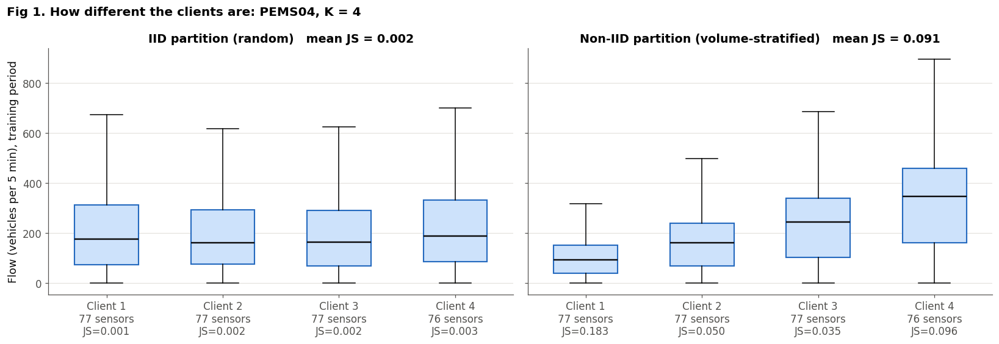

In [ ]:
# ---------- Fig 1: client heterogeneity --------------------------------------------------------
_b = get_bundle(CFG.primary_dataset)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True)
for ax, scheme, title in zip(axes, ("iid", "noniid"), ("IID partition (random)", "Non-IID partition (volume-stratified)")):
    parts = partition_sensors(_b, CFG.num_clients, scheme, seed=0)
    rep = heterogeneity_report(_b, parts)
    data = [_b.flow_train[:, p][::6].ravel() for p in parts]   # every 6th step keeps the plot light
    bp = ax.boxplot(data, widths=0.55, showfliers=False, patch_artist=True,
                    medianprops=dict(color=INK, lw=1.6))
    for patch in bp["boxes"]:
        patch.set(facecolor="#cde2fb", edgecolor="#256abf", lw=1.4)
    ax.set_xticks(range(1, len(parts) + 1),
                  [f"Client {k + 1}\n{len(p)} sensors\nJS={j:.3f}" for k, (p, j) in enumerate(zip(parts, rep["js_per_client"]))])
    ax.set_title(f"{title}   mean JS = {rep['js_mean']:.3f}")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Flow (vehicles per 5 min), training period")
fig.suptitle(f"Fig 1. How different the clients are: {CFG.primary_dataset}, K = {CFG.num_clients}",
             fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "fig1_client_heterogeneity")

saved fig2_convergence.png / .pdf


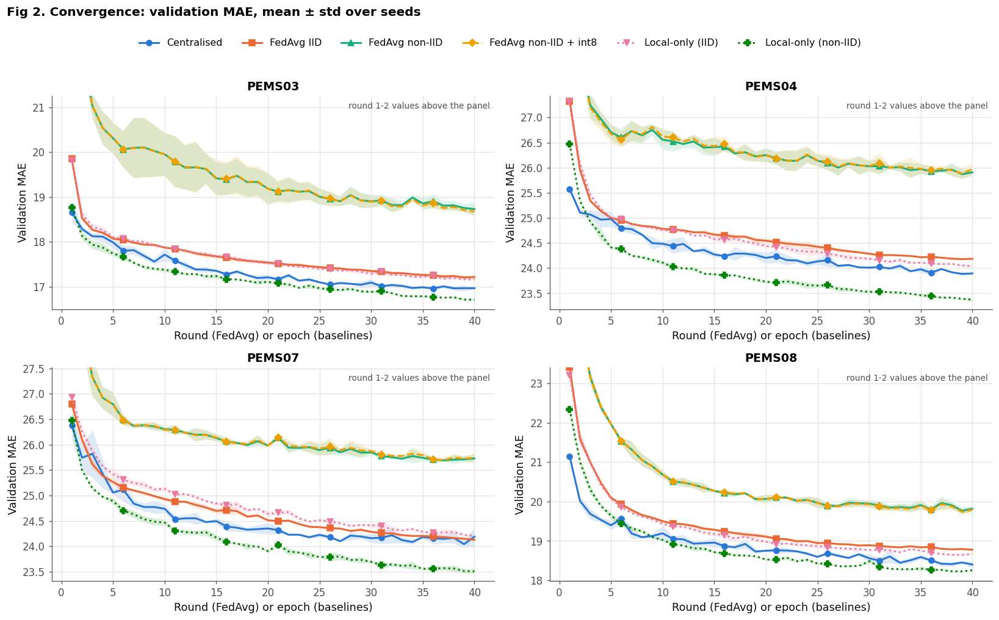

In [ ]:
# ---------- Fig 2: convergence curves ---------------------------------------------------------
fig, axes = _grid_axes(len(DATASETS_PRESENT))
for ax, ds in zip(axes, DATASETS_PRESENT):
    for meth in METHOD_ORDER:
        c = _curves(MAIN_RESULTS, ds, meth)
        if c is None:
            continue
        x, mu, sd, _ = c
        col, ls, mk = STYLE[meth]
        ax.plot(x, mu, color=col, ls=ls, marker=mk, markevery=max(1, len(x) // 8), label=meth)
        ax.fill_between(x, mu - sd, mu + sd, color=col, alpha=0.15, lw=0)
    # Zoom on what matters: round 1 of FedAvg starts far higher and would flatten the rest.
    tails = [_curves(MAIN_RESULTS, ds, m)[1] for m in METHOD_ORDER if _curves(MAIN_RESULTS, ds, m)]
    lo = min(t.min() for t in tails)
    hi = max(t[min(2, len(t) - 1)] for t in tails)
    ax.set_ylim(lo - 0.05 * (hi - lo), hi + 0.05 * (hi - lo))
    ax.annotate("round 1-2 values above the panel", xy=(0.99, 0.97), xycoords="axes fraction",
                ha="right", va="top", fontsize=9, color=INK2)
    ax.set_title(ds)
    ax.set_xlabel("Round (FedAvg) or epoch (baselines)")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_ylabel("Validation MAE")
fig.legend(handles=_method_handles([m for m in METHOD_ORDER if m in set(DF_MAIN["method"])]),
           loc="upper center", ncol=6, bbox_to_anchor=(0.5, 1.03), fontsize=10.5)
fig.suptitle("Fig 2. Convergence: validation MAE, mean ± std over seeds", fontweight="bold",
             x=0.01, ha="left", y=1.07)
fig.tight_layout()
save_fig(fig, "fig2_convergence")

saved fig3_accuracy_vs_bytes.png / .pdf


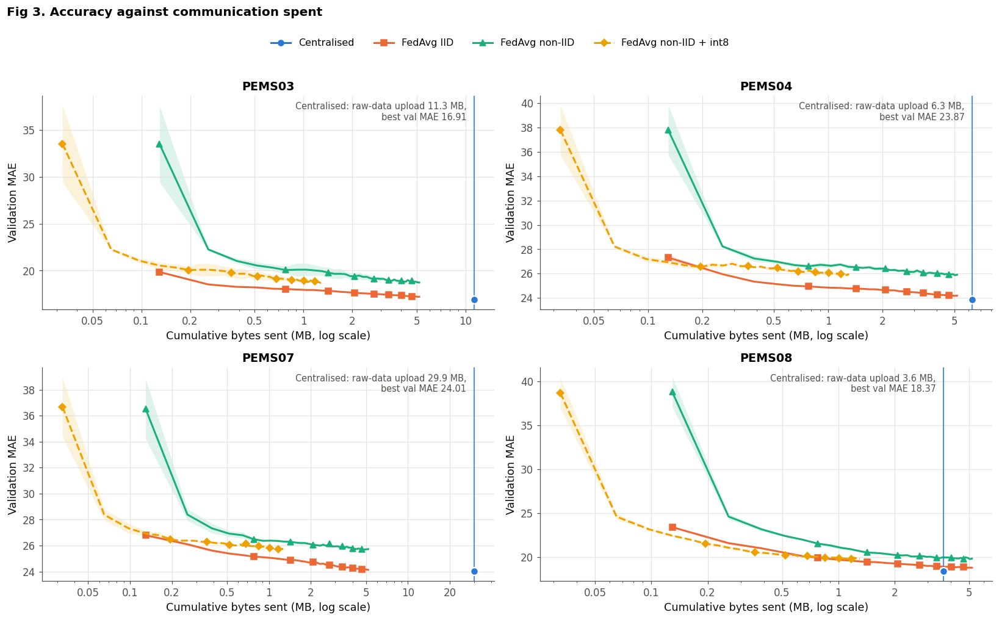

In [ ]:
# ---------- Fig 3: accuracy vs cumulative communication ---------------------------------------
fig, axes = _grid_axes(len(DATASETS_PRESENT))
for ax, ds in zip(axes, DATASETS_PRESENT):
    for meth in ("FedAvg IID", "FedAvg non-IID", "FedAvg non-IID + int8"):
        c = _curves(MAIN_RESULTS, ds, meth)
        if c is None:
            continue
        _, mu, sd, rs = c
        mb = np.array([h["cum_bytes"] for h in rs[0]["history"]]) / 1e6
        col, ls, mk = STYLE[meth]
        ax.plot(mb, mu, color=col, ls=ls, marker=mk, markevery=max(1, len(mb) // 8), label=meth)
        ax.fill_between(mb, mu - sd, mu + sd, color=col, alpha=0.15, lw=0)
    cent = DF_MAIN[(DF_MAIN.dataset == ds) & (DF_MAIN.method == "Centralised")]
    if len(cent):
        raw_mb = cent["raw_upload_mb"].iloc[0]
        cent_val = np.mean([r["best_val_mae"] for r in MAIN_RESULTS
                            if r["spec"]["dataset"] == ds and r["method"] == "Centralised"])
        ax.axvline(raw_mb, color=STYLE["Centralised"][0], ls="-", lw=1.4, alpha=0.8)
        ax.scatter([raw_mb], [cent_val], color=STYLE["Centralised"][0], marker="o", s=70, zorder=5,
                   edgecolor=SURFACE, linewidth=1.5)
        ax.annotate(f"Centralised: raw-data upload {raw_mb:.1f} MB,\nbest val MAE {cent_val:.2f}",
                    xy=(raw_mb, 0.97), xycoords=("data", "axes fraction"), xytext=(-8, 0),
                    textcoords="offset points", ha="right", va="top", fontsize=9.5, color=INK2)
    plain_log_x(ax)
    ax.set_title(ds)
    ax.set_xlabel("Cumulative bytes sent (MB, log scale)")
    ax.set_ylabel("Validation MAE")
fig.legend(handles=_method_handles(["Centralised", "FedAvg IID", "FedAvg non-IID", "FedAvg non-IID + int8"]),
           loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.03), fontsize=10.5)
fig.suptitle("Fig 3. Accuracy against communication spent", fontweight="bold", x=0.01, ha="left", y=1.07)
fig.tight_layout()
save_fig(fig, "fig3_accuracy_vs_bytes")

saved fig4_test_accuracy_bars.png / .pdf


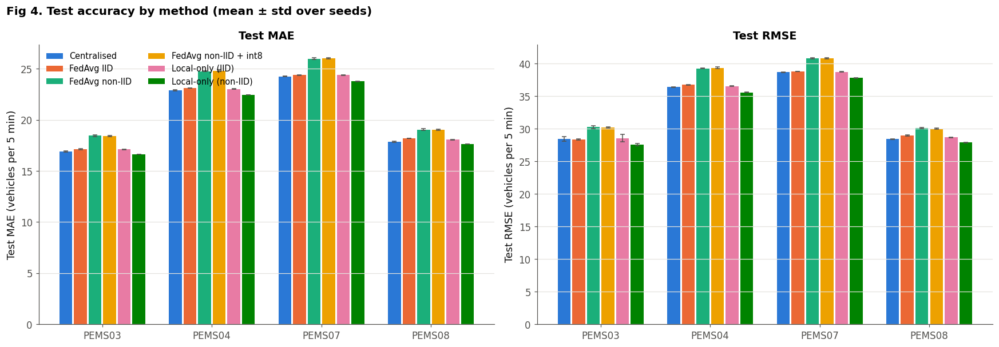

In [ ]:
# ---------- Fig 4: test MAE and RMSE by method and dataset ------------------------------------
methods_present = [m for m in METHOD_ORDER if m in set(DF_MAIN["method"])]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6))
agg = DF_MAIN.groupby(["dataset", "method"])[["test_mae", "test_rmse"]].agg(["mean", "std"])
width = 0.8 / len(methods_present)
xs = np.arange(len(DATASETS_PRESENT))
for ax, metric, label in zip(axes, ("test_mae", "test_rmse"), ("Test MAE", "Test RMSE")):
    for i, meth in enumerate(methods_present):
        mu = [agg.loc[(ds, meth), (metric, "mean")] for ds in DATASETS_PRESENT]
        sd = [np.nan_to_num(agg.loc[(ds, meth), (metric, "std")]) for ds in DATASETS_PRESENT]
        ax.bar(xs + (i - (len(methods_present) - 1) / 2) * width, mu, width * 0.88, yerr=sd,
               color=STYLE[meth][0], label=meth, capsize=2.5, error_kw=dict(ecolor=INK2, lw=1))
    ax.set_xticks(xs, DATASETS_PRESENT)
    ax.set_ylabel(f"{label} (vehicles per 5 min)")
    ax.set_title(label)
    ax.grid(axis="x", visible=False)
axes[0].legend(ncol=2, fontsize=9.5, loc="upper left")
fig.suptitle("Fig 4. Test accuracy by method (mean ± std over seeds)", fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "fig4_test_accuracy_bars")

saved fig5_horizon_mae.png / .pdf


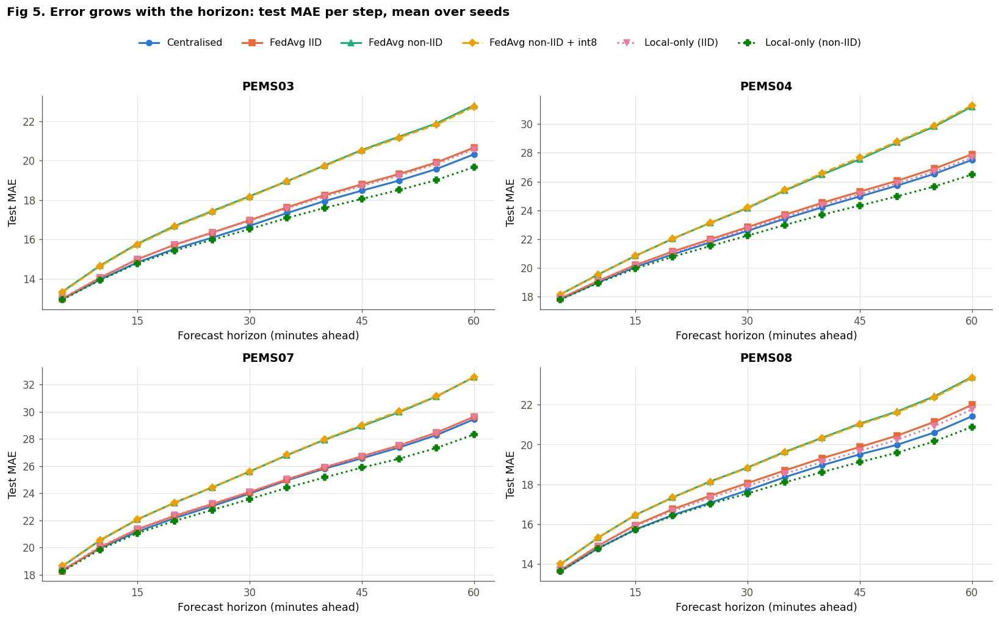

In [ ]:
# ---------- Fig 5: error across forecast horizons ---------------------------------------------
fig, axes = _grid_axes(len(DATASETS_PRESENT))
mins = 5 * np.arange(1, CFG.horizon + 1)
for ax, ds in zip(axes, DATASETS_PRESENT):
    for meth in methods_present:
        rs = [r for r in MAIN_RESULTS if r["spec"]["dataset"] == ds and r["method"] == meth]
        arr = np.array([r["test"]["mae_h"] for r in rs])
        col, ls, mk = STYLE[meth]
        ax.plot(mins, arr.mean(0), color=col, ls=ls, marker=mk, label=meth)
    ax.set_xticks([15, 30, 45, 60])
    ax.set_title(ds)
    ax.set_xlabel("Forecast horizon (minutes ahead)")
    ax.set_ylabel("Test MAE")
fig.legend(handles=_method_handles(methods_present), loc="upper center", ncol=6,
           bbox_to_anchor=(0.5, 1.03), fontsize=10.5)
fig.suptitle("Fig 5. Error grows with the horizon: test MAE per step, mean over seeds",
             fontweight="bold", x=0.01, ha="left", y=1.07)
fig.tight_layout()
save_fig(fig, "fig5_horizon_mae")

saved fig6_per_client_mae.png / .pdf


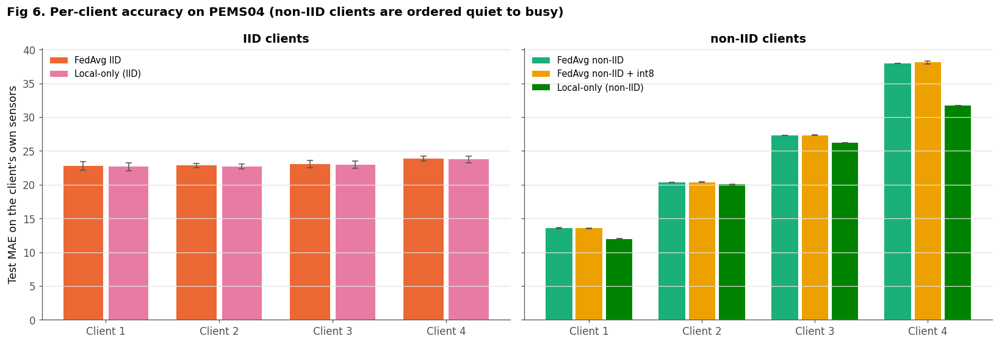

In [ ]:
# ---------- Fig 6: per-client fairness --------------------------------------------------------
ds = CFG.primary_dataset
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True)
for ax, part, meths in zip(axes, ("IID", "non-IID"),
                           (("FedAvg IID", "Local-only (IID)"),
                            ("FedAvg non-IID", "FedAvg non-IID + int8", "Local-only (non-IID)"))):
    width = 0.8 / len(meths)
    for i, meth in enumerate(meths):
        rs = [r for r in MAIN_RESULTS if r["spec"]["dataset"] == ds and r["method"] == meth]
        if not rs:
            continue
        arr = np.array([[c["mae"] for c in r["test"]["per_client"]] for r in rs])
        k = np.arange(arr.shape[1])
        ax.bar(k + (i - (len(meths) - 1) / 2) * width, arr.mean(0), width * 0.88,
               yerr=arr.std(0), color=STYLE[meth][0], label=meth, capsize=3,
               error_kw=dict(ecolor=INK2, lw=1))
    ax.set_xticks(k, [f"Client {i + 1}" for i in k])
    ax.set_title(f"{part} clients")
    ax.legend(fontsize=9.5, loc="upper left")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Test MAE on the client's own sensors")
fig.suptitle(f"Fig 6. Per-client accuracy on {ds} (non-IID clients are ordered quiet to busy)",
             fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
save_fig(fig, "fig6_per_client_mae")

saved fig7_tradeoff_pareto.png / .pdf


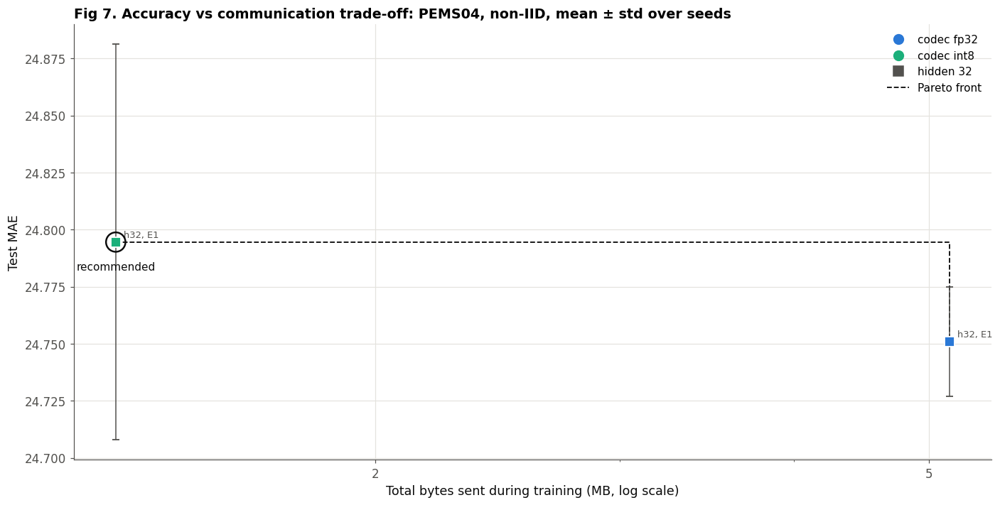

In [ ]:
# ---------- Fig 7: trade-off sweep with Pareto front ------------------------------------------
fig, ax = plt.subplots(figsize=(13, 6.6))
for _, r in TAB_SWEEP.iterrows():
    ax.errorbar(r["total_mb"], r["test_mae"], yerr=np.nan_to_num(r["test_mae_std"]),
                fmt=HIDDEN_MARKER.get(int(r["hidden"]), "o"), ms=9, color=CODEC_COLOUR[r["codec"]],
                mec=SURFACE, mew=1.2, ecolor=INK2, elinewidth=1, capsize=3, zorder=3)
    ax.annotate(f"h{int(r['hidden'])}, E{int(r['local_epochs'])}", (r["total_mb"], r["test_mae"]),
                xytext=(7, 4), textcoords="offset points", fontsize=8.5, color=INK2)
front = TAB_SWEEP[TAB_SWEEP["pareto"]].sort_values("total_mb")
ax.step(front["total_mb"], front["test_mae"], where="post", color=INK, lw=1.2, ls="--", zorder=2)
ax.scatter([RECOMMENDED["total_mb"]], [RECOMMENDED["test_mae"]], s=320, facecolor="none",
           edgecolor=INK, lw=1.6, zorder=4)
ax.annotate("recommended", (RECOMMENDED["total_mb"], RECOMMENDED["test_mae"]), xytext=(0, -26),
            textcoords="offset points", ha="center", fontsize=10, color=INK)
plain_log_x(ax)
ax.set_xlabel("Total bytes sent during training (MB, log scale)")
ax.set_ylabel("Test MAE")
legend_items = ([Line2D([], [], color=c, marker="o", ls="", ms=9, label=f"codec {k}") for k, c in CODEC_COLOUR.items()
                 if k in set(TAB_SWEEP["codec"])] +
                [Line2D([], [], color=INK2, marker=m, ls="", ms=9, label=f"hidden {h}") for h, m in HIDDEN_MARKER.items()
                 if h in set(TAB_SWEEP["hidden"])] +
                [Line2D([], [], color=INK, ls="--", lw=1.2, label="Pareto front")])
ax.legend(handles=legend_items, ncol=1, fontsize=10, loc="upper right")
ax.set_title(f"Fig 7. Accuracy vs communication trade-off: {CFG.primary_dataset}, non-IID, mean ± std over seeds",
             loc="left")
fig.tight_layout()
save_fig(fig, "fig7_tradeoff_pareto")

saved fig8_bytes_per_round.png / .pdf


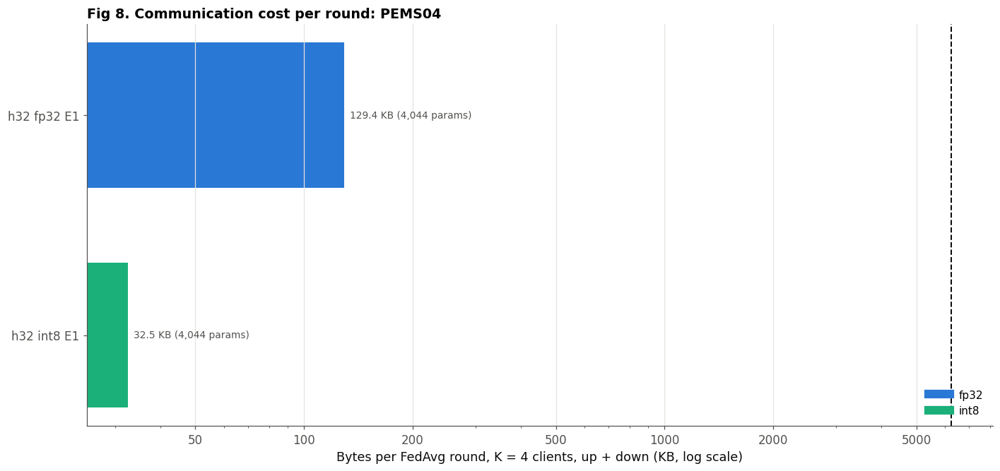

In [ ]:
# ---------- Fig 8: bytes per round by configuration vs raw upload -----------------------------
fig, ax = plt.subplots(figsize=(13, 6.2))
tab8 = TAB_SWEEP.sort_values("kb_per_round")
y = np.arange(len(tab8))
ax.barh(y, tab8["kb_per_round"], color=[CODEC_COLOUR[c] for c in tab8["codec"]], height=0.66)
for yi, (kb, n) in enumerate(zip(tab8["kb_per_round"], tab8["n_params"])):
    ax.annotate(f"{kb:.1f} KB ({int(n):,} params)", (kb, yi), xytext=(5, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK2)
raw_mb = DF_MAIN[(DF_MAIN.dataset == CFG.primary_dataset)]["raw_upload_mb"].iloc[0]
ax.axvline(raw_mb * 1e3, color=INK, ls="--", lw=1.3)
ax.annotate(f"one-off raw-data upload for centralised training: {raw_mb:.2f} MB",
            (raw_mb * 1e3, len(tab8) - 0.5), xytext=(-6, 0), textcoords="offset points",
            ha="right", va="top", fontsize=9.5, color=INK)
ax.set_yticks(y, tab8["config"])
plain_log_x(ax)
ax.set_xlabel(f"Bytes per FedAvg round, K = {CFG.num_clients} clients, up + down (KB, log scale)")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Line2D([], [], color=c, lw=8, label=k) for k, c in CODEC_COLOUR.items()
                   if k in set(tab8["codec"])], loc="lower right", fontsize=10)
ax.set_title(f"Fig 8. Communication cost per round: {CFG.primary_dataset}", loc="left")
fig.tight_layout()
save_fig(fig, "fig8_bytes_per_round")

saved fig9_cumulative_bytes.png / .pdf


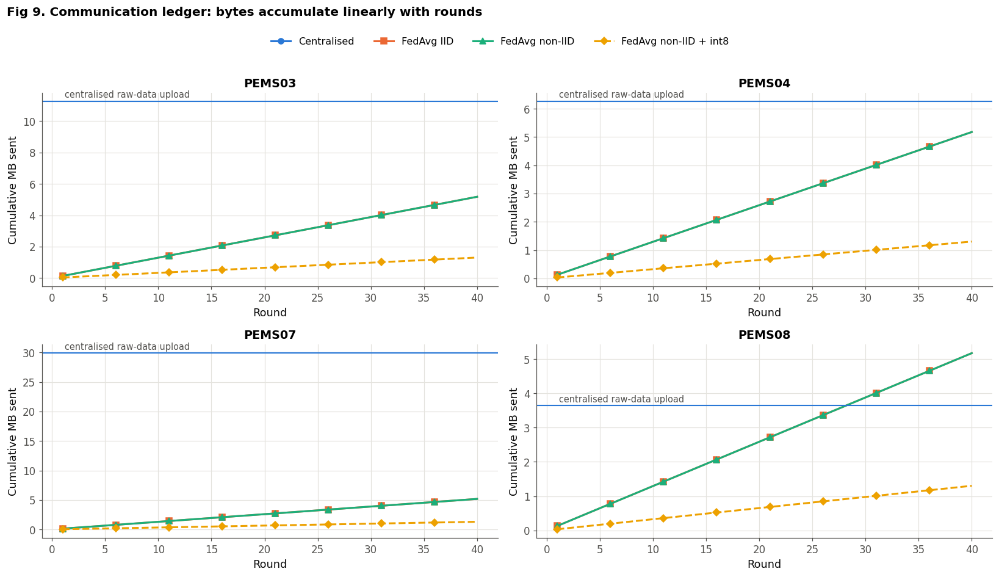

In [ ]:
# ---------- Fig 9: communication ledger over rounds -------------------------------------------
fig, axes = _grid_axes(len(DATASETS_PRESENT), h=8.0)
for ax, ds in zip(axes, DATASETS_PRESENT):
    for meth in ("FedAvg IID", "FedAvg non-IID", "FedAvg non-IID + int8"):
        rs = [r for r in MAIN_RESULTS if r["spec"]["dataset"] == ds and r["method"] == meth]
        if not rs:
            continue
        x = [h["round"] for h in rs[0]["history"]]
        cum = np.array([h["cum_bytes"] for h in rs[0]["history"]]) / 1e6
        col, ls, mk = STYLE[meth]
        ax.plot(x, cum, color=col, ls=ls, marker=mk, markevery=max(1, len(x) // 8), label=meth)
    cent = DF_MAIN[(DF_MAIN.dataset == ds) & (DF_MAIN.method == "Centralised")]
    if len(cent):
        ax.axhline(cent["raw_upload_mb"].iloc[0], color=STYLE["Centralised"][0], lw=1.4)
        ax.annotate("centralised raw-data upload", (1, cent["raw_upload_mb"].iloc[0]), xytext=(2, 4),
                    textcoords="offset points", fontsize=9.5, color=INK2)
    ax.set_title(ds)
    ax.set_xlabel("Round")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_ylabel("Cumulative MB sent")
fig.legend(handles=_method_handles(["Centralised", "FedAvg IID", "FedAvg non-IID", "FedAvg non-IID + int8"]),
           loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.03), fontsize=10.5)
fig.suptitle("Fig 9. Communication ledger: bytes accumulate linearly with rounds", fontweight="bold",
             x=0.01, ha="left", y=1.07)
fig.tight_layout()
save_fig(fig, "fig9_cumulative_bytes")

## 15. Live demo (runs in seconds, no GPU needed)

Two short demonstrations for a presentation, both independent of the long experiments above.

**15.1 Forecast with a saved federated model.** Loads the best FedAvg non-IID + int8 model of the
primary dataset from `checkpoints/` (no retraining), forecasts one full test day one hour ahead,
and plots the forecast against the real flow for the quietest and the busiest client.

**15.2 One live FedAvg round.** Runs a real round of the protocol on a small slice of the training
data with the int8 codec and prints every message and its measured size in bytes, so the audience
can see that only about 4 KB per client crosses the network and that no raw data is sent.

saved fig10_live_forecast_demo.png / .pdf


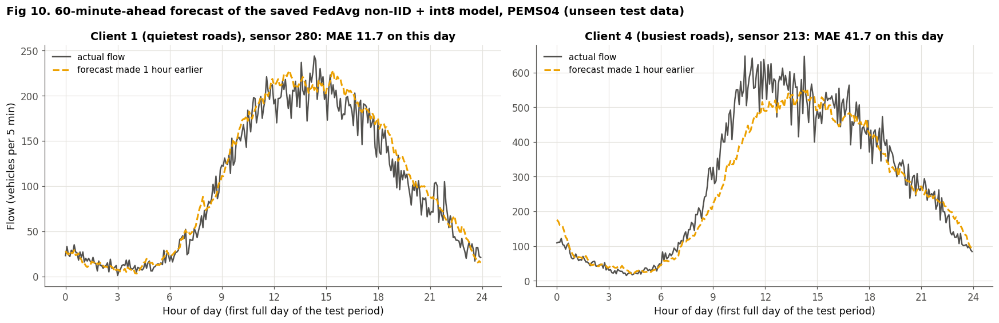

In [ ]:
# ---------- 15.1 Forecast with a saved federated model ----------------------------------------
def load_checkpoint(spec: RunSpec) -> nn.Module:
    """Rebuild the model of a finished run from its saved best weights."""
    weights = torch.load(os.path.join(CKPT_DIR, spec.key(CFG) + ".pt"), map_location=DEVICE)
    model = CompactGRU(hidden=spec.hidden, layers=spec.layers).to(DEVICE)
    set_weights(model, [w.to(DEVICE) for w in weights[0]])
    return model.eval()


DEMO_SPEC = RunSpec(dataset=CFG.primary_dataset, algo="fedavg", partition="noniid", seed=0,
                    hidden=CFG.hidden_size, layers=CFG.num_layers, codec="int8",
                    local_epochs=CFG.local_epochs, rounds=CFG.rounds)
if not os.path.exists(os.path.join(CKPT_DIR, DEMO_SPEC.key(CFG) + ".pt")):
    print("Demo checkpoint not found; run the main grid first.")
else:
    demo_bundle = get_bundle(DEMO_SPEC.dataset)
    demo_parts = partition_sensors(demo_bundle, CFG.num_clients, "noniid", 0)
    demo_mean, demo_std = federated_scaler(demo_bundle, demo_parts)
    demo_model = load_checkpoint(DEMO_SPEC)

    t_start = demo_bundle.splits["test"][0] + STEPS_PER_DAY - (
        demo_bundle.splits["test"][0] % STEPS_PER_DAY)           # first midnight of the test period
    day = np.arange(t_start, t_start + STEPS_PER_DAY)
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), sharex=True)
    for ax, k, label in zip(axes, (0, CFG.num_clients - 1), ("quietest", "busiest")):
        cd = ClientData(demo_bundle, demo_parts[k], demo_mean, demo_std, CFG, DEVICE)
        sensor = int(np.argsort(demo_bundle.flow_train[:, demo_parts[k]].mean(0))[len(demo_parts[k]) // 2])
        starts = torch.as_tensor(day - CFG.input_len - CFG.horizon + 1, device=DEVICE)  # target at step 12
        with torch.no_grad():
            x, _, y = cd.make_batch(starts)
            pred = (demo_model(x) * demo_std + demo_mean).clamp(min=0)
        pred_1h = pred.view(len(day), cd.n_sensors, CFG.horizon)[:, sensor, -1].cpu().numpy()
        true_1h = y.view(len(day), cd.n_sensors, CFG.horizon)[:, sensor, -1].cpu().numpy()
        hours = np.arange(len(day)) / 12
        ax.plot(hours, true_1h, color=INK2, lw=1.6, label="actual flow")
        ax.plot(hours, pred_1h, color=STYLE["FedAvg non-IID + int8"][0], lw=2.0, ls="--",
                label="forecast made 1 hour earlier")
        mae = float(np.abs(pred_1h - true_1h).mean())
        ax.set_title(f"Client {k + 1} ({label} roads), sensor {int(demo_parts[k][sensor])}: "
                     f"MAE {mae:.1f} on this day")
        ax.set_xlabel("Hour of day (first full day of the test period)")
        ax.set_xticks(range(0, 25, 3))
        ax.legend(loc="upper left", fontsize=10)
        del cd
    axes[0].set_ylabel("Flow (vehicles per 5 min)")
    fig.suptitle(f"Fig 10. 60-minute-ahead forecast of the saved FedAvg non-IID + int8 model, "
                 f"{DEMO_SPEC.dataset} (unseen test data)", fontweight="bold", x=0.01, ha="left")
    fig.tight_layout()
    save_fig(fig, "fig10_live_forecast_demo")

In [ ]:
# ---------- 15.2 One live FedAvg round with the byte ledger -----------------------------------
demo_cfg = replace(CFG, max_windows=300)             # small slice: the round takes a few seconds
demo_bundle = get_bundle(CFG.primary_dataset)
demo_parts = partition_sensors(demo_bundle, demo_cfg.num_clients, "noniid", 0)
demo_clients, demo_mean, demo_std = build_clients(demo_bundle, demo_parts, demo_cfg)
set_seed(0)
model = CompactGRU(hidden=CFG.hidden_size).to(DEVICE)
global_w = get_weights(model)
codec = Codec("int8", [w.shape for w in global_w])
w_k = np.array([c.num_sequences("train") for c in demo_clients], float)
w_k /= w_k.sum()
raw_bytes = [demo_bundle.flow_train[:, p].size * CFG.raw_bytes_per_reading for p in demo_parts]

print(f"Model: CompactGRU, {codec.P:,} parameters. Codec: int8. Clients: {len(demo_clients)}\n")
t0 = time.time()
down = codec.encode(global_w)                        # round 1: clients hold nothing yet
client_view = codec.decode(down, DEVICE)
print(f"SERVER -> each client : global model          {len(down):>6,} bytes")
agg = [torch.zeros_like(w) for w in global_w]
up_total = 0
for k, cd in enumerate(demo_clients):
    set_weights(model, client_view)
    opt = torch.optim.Adam(model.parameters(), lr=CFG.lr)
    loss = train_epochs(model, cd, 1, opt, np.random.default_rng(0), CFG.grad_clip)
    payload = codec.encode([p - c for p, c in zip(get_weights(model), client_view)])
    up_total += len(payload)
    for a, d in zip(agg, codec.decode(payload, DEVICE)):
        a += w_k[k] * d
    print(f"client {k + 1} -> SERVER   : model update (loss {loss:.3f}) {len(payload):>6,} bytes   "
          f"| its raw training data would be {raw_bytes[k] / 1e6:5.2f} MB")
global_w = [c + a for c, a in zip(client_view, agg)]
round_bytes = up_total + len(down) * len(demo_clients)
print(f"\nRound total: {round_bytes:,} bytes ({round_bytes / 1e3:.1f} KB) in {time.time() - t0:.1f} s. "
      f"Raw training data of all clients: {sum(raw_bytes) / 1e6:.2f} MB, which never leaves the clients.")
del demo_clients

Model: CompactGRU, 4,044 parameters. Codec: int8. Clients: 4

SERVER -> each client : global model           4,068 bytes
client 1 -> SERVER   : model update (loss 0.674)  4,068 bytes   | its raw training data would be  1.57 MB
client 2 -> SERVER   : model update (loss 0.610)  4,068 bytes   | its raw training data would be  1.57 MB
client 3 -> SERVER   : model update (loss 0.775)  4,068 bytes   | its raw training data would be  1.57 MB
client 4 -> SERVER   : model update (loss 1.146)  4,068 bytes   | its raw training data would be  1.55 MB

Round total: 32,544 bytes (32.5 KB) in 9.8 s. Raw training data of all clients: 6.26 MB, which never leaves the clients.


## 16. Summary and export

Prints the key numbers for the report and lists every file produced. All outputs are on Drive in
`phase1_outputs/`:
* `tables/` — CSV, Markdown and LaTeX tables (Tables 1 to 4, plus every individual run).
* `figures/` — Figures 1 to 10 as 300 dpi PNG and vector PDF.
* `runs/` — one JSON per run with the full per-round history (the raw evidence for every number).
* `checkpoints/` — best model weights per run.
* `tensorboard/` — dashboard logs (mirrored from `/content/tb_logs` after every run). To view
  them later in a fresh session, run `%load_ext tensorboard` then `%tensorboard --logdir "<that folder>"`.

In [ ]:
print("=" * 90)
print("PS-003 PHASE 1 SUMMARY")
print("=" * 90)
print(f"Clients: K = {CFG.num_clients}   Seeds: {list(CFG.seeds)}   Model: CompactGRU h={CFG.hidden_size}, "
      f"{count_params(CompactGRU(hidden=CFG.hidden_size)):,} parameters")
print(f"Rounds: {CFG.rounds}   Local epochs: {CFG.local_epochs}   Chronological split: "
      f"{CFG.train_frac:.0%} / {CFG.val_frac:.0%} / {1 - CFG.train_frac - CFG.val_frac:.0%}\n")
print(TAB_HEAD.round(2).to_string(index=False))
print(f"\nRecommended low-cost configuration ({CFG.primary_dataset}, non-IID): {RECOMMENDED['config']}, "
      f"test MAE {RECOMMENDED['test_mae']:.3f}, {RECOMMENDED['kb_per_round']:.2f} KB per round, "
      f"{RECOMMENDED['total_mb']:.3f} MB in total")
print("\nFiles written:")
for d in (TAB_DIR, FIG_DIR):
    for f in sorted(os.listdir(d)):
        print("  ", os.path.join(os.path.basename(d), f))
print(f"\nRun records: {len(os.listdir(RUNS_DIR))} JSON files in {RUNS_DIR}")

PS-003 PHASE 1 SUMMARY
Clients: K = 4   Seeds: [0, 1, 2]   Model: CompactGRU h=32, 4,044 parameters
Rounds: 40   Local epochs: 1   Chronological split: 60% / 20% / 20%

dataset  FL gap vs central, MAE %  non-IID penalty, MAE %  FedAvg gain vs local (non-IID), MAE %  int8 MAE change %  int8 bytes saved %  FedAvg fp32 MB / raw upload MB  FedAvg int8 MB / raw upload MB  rounds to 1.1x central (IID)  rounds to 1.1x central (non-IID)
 PEMS03                      1.45                    7.61                                 -10.90              -0.21               74.85                            0.46                            0.12                          2.33                             32.00
 PEMS04                      1.08                    7.03                                 -10.25               0.18               74.85                            0.83                            0.21                          2.00                             20.00
 PEMS07                      0.49      